# PathSnap — Exploratory Data Analysis (EDA)
**Course:** UE24CS352A Machine Learning · **Task:** distributed map-matching & route reconstruction

This notebook covers the **dataset-exploration** part of the hackathon (see *Dataset Exploration.pdf*, sections 4, 5, 8, 9 and *Deliverables.pdf*, section 2.2).

**What it produces**
| Output | Where |
|---|---|
| Dataset inventory (trips, files, sizes, observation counts) | table + `eda_outputs/trip_summary.csv` |
| GPS data-quality analysis (missing values, timestamps, gaps, speeds, jumps) | tables + figures |
| Road-network analysis (nodes, arcs, components, isolated nodes, one-way share) | tables + figures |
| Reference-route analysis (encoding, validity, continuity) | tables + figures |
| GPS-noise analysis: distance from GPS points to the reference route → candidate-radius evidence | figures |
| Interactive **Folium** maps (GPS + road network + reference route + gaps) | `eda_outputs/maps/*.html` |
| Auto-generated findings / data-quality log | printed at the end |

**How to run (Colab):** upload `Student_folder.zip` to the Colab file panel (`/content`) *or* put it in Google Drive (`MyDrive`), then **Runtime → Run all**. No GPU needed (~2–4 min).

**Partition rule:** EDA uses only `train` (80 trips) and `student_test` (10 trips). Every table/plot is labelled with its partition. Anything *learned* from data (e.g. a candidate radius) is derived from `train` only and merely *checked* on `student_test`.

## 0. Setup & data location

In [ ]:
import os, sys, glob, zipfile, shutil, math, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import seaborn as sns
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from tqdm.auto import tqdm
from IPython.display import display

try:
    import folium
    from folium.plugins import MarkerCluster
except ImportError:
    get_ipython().system("pip -q install folium")
    import folium
    from folium.plugins import MarkerCluster

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
PAL = {"train": "#1f77b4", "student_test": "#ff7f0e"}
print("folium", folium.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

folium 0.20.0 | pandas 2.2.3 | numpy 2.4.6


In [ ]:
# ── Locate the data ──────────────────────────────────────────────────────────
# If auto-detection fails, set DATA_ROOT by hand to the folder that contains
# the sub-folders "train" and "student_test", e.g. "/content/Student folder"
DATA_ROOT = None

EXTRACT_DIR = "/content/pathsnap_data"

def _find_root(base):
    for dp, dn, _ in os.walk(base):
        if "train" in dn and "student_test" in dn:
            return dp
    return None

if DATA_ROOT is None:
    # 1) data already extracted somewhere in /content ?
    DATA_ROOT = _find_root("/content") if os.path.isdir("/content") else None

if DATA_ROOT is None:
    # 2) find the zip (Colab file panel or mounted Drive)
    zips = [p for pat in ["/content/*.zip", "/content/drive/MyDrive/*.zip", "/content/drive/MyDrive/*/*.zip"]
            for p in glob.glob(pat) if "student" in os.path.basename(p).lower() and "pathsnap" not in os.path.basename(p).lower()]
    if not zips:
        try:                                    # 3) offer an upload dialog
            from google.colab import files
            print("Zip not found - please upload Student_folder.zip")
            up = files.upload(); zips = [f"/content/{k}" for k in up if k.endswith(".zip")]
        except Exception as e:
            raise FileNotFoundError("Student_folder.zip not found. Upload it to /content or set DATA_ROOT.") from e
    print("Using zip:", zips[0])
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(EXTRACT_DIR)
    DATA_ROOT = _find_root(EXTRACT_DIR)

assert DATA_ROOT, "Could not find a folder containing 'train' and 'student_test'."
PARTS = {"train": os.path.join(DATA_ROOT, "train"), "student_test": os.path.join(DATA_ROOT, "student_test")}
print("DATA_ROOT:", DATA_ROOT)
for p, d in PARTS.items():
    print(f"  {p:13s} -> {len(os.listdir(d))} trip folders")

OUT = "eda_outputs"; FIG = f"{OUT}/figures"; MAPS = f"{OUT}/maps"
for d in (OUT, FIG, MAPS): os.makedirs(d, exist_ok=True)

Zip not found - please upload Student_folder.zip


Saving Student folder.zip to Student folder.zip
Using zip: /content/Student folder.zip
DATA_ROOT: /content/pathsnap_data/Student folder
  train         -> 80 trip folders
  student_test  -> 10 trip folders


## 1. Raw file format
Per *Dataset Exploration.pdf* every trip has four **header-less, whitespace-separated** files. We do **not** just trust that description — the next cells print the raw bytes and parse the files, then later cells validate row counts, ranges and index relationships.

| File | Columns | Meaning |
|---|---|---|
| `.track` | lon, lat, t(s) | noisy GPS observations |
| `.nodes` | lon, lat | road-network nodes — **row index = node_id** |
| `.arcs` | from_node, to_node | directed road segments — **row index = arc_id** |
| `.route` | arc_id | reference route: chronological arc_ids |

> Key point: a GPS row does **not** map to a node/arc row. `.route` lists *arcs*, not GPS points — so there are no per-GPS-point labels, we will have to derive them later.

In [ ]:
EXT = ["track", "nodes", "arcs", "route"]

def trip_dir(part, tid): return os.path.join(PARTS[part], tid)
def trip_file(part, tid, ext): return os.path.join(trip_dir(part, tid), f"{tid}.{ext}")

def _read_table(path, dtype):
    try:
        return pd.read_csv(path, sep=r"\s+", header=None, dtype=dtype, engine="c").to_numpy()
    except pd.errors.EmptyDataError:
        return np.empty((0, 0), dtype=dtype)

def load_trip(part, tid):
    """Return dict of numpy arrays: track (n,3) float, nodes (N,2) float, arcs (M,2) int, route (K,) int."""
    return dict(
        track=_read_table(trip_file(part, tid, "track"), np.float64),
        nodes=_read_table(trip_file(part, tid, "nodes"), np.float64),
        arcs =_read_table(trip_file(part, tid, "arcs"),  np.int64),
        route=_read_table(trip_file(part, tid, "route"), np.int64).ravel(),
    )

TRIP_IDS = {p: sorted(d for d in os.listdir(PARTS[p]) if os.path.isdir(os.path.join(PARTS[p], d))) for p in PARTS}

# raw look at one trip: first bytes, shapes, dtypes
part0, tid0 = "train", TRIP_IDS["train"][0]
print(f"Raw bytes of first lines  (trip {tid0}, partition {part0}) — note the Windows line endings (\\r\\n):")
for e in EXT:
    with open(trip_file(part0, tid0, e), "rb") as f:
        print(f"  .{e:6s}", f.read(70))
T0 = load_trip(part0, tid0)
print("\nParsed shapes / dtypes:")
for k, v in T0.items(): print(f"  {k:6s} shape={v.shape}  dtype={v.dtype}")
display(pd.DataFrame(T0["track"][:5], columns=["lon", "lat", "t_sec"]))

Raw bytes of first lines  (trip 00000001, partition train) — note the Windows line endings (\r\n):
  .track  b'8.595203\t49.844053\t1.000000\r\n8.595294\t49.844441\t2.000000\r\n8.595352\t49.'
  .nodes  b'8.581679\t49.857880\n8.584637\t49.858295\n8.580173\t49.858567\n8.584392\t49.8'
  .arcs   b'0\t281\n0\t1\n0\t5\n1\t0\n1\t40750\n1\t59281\n1\t3\n2\t3\n2\t276\n2\t280\n3\t2\n3\t622\n3\t1\n3\t'
  .route  b'2641\n64973\n133948\n133949\n139208\n133950\n8970\n133951\n64139\n139211\n133952'

Parsed shapes / dtypes:
  track  shape=(1315, 3)  dtype=float64
  nodes  shape=(88809, 2)  dtype=float64
  arcs   shape=(165790, 2)  dtype=int64
  route  shape=(525,)  dtype=int64


,lon,lat,t_sec
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


## 2. Dataset inventory *(deliverable: "Dataset inventory")*
File availability, file sizes and trip counts per partition, plus a check that the split is leak-free (no trip ID appears in two partitions).

In [ ]:
rows = []
for part in PARTS:
    for tid in TRIP_IDS[part]:
        r = dict(partition=part, trip_id=tid)
        present = set(os.listdir(trip_dir(part, tid)))
        for e in EXT:
            fn = f"{tid}.{e}"
            r[f"has_{e}"] = fn in present
            r[f"kb_{e}"] = os.path.getsize(trip_file(part, tid, e)) / 1024 if fn in present else np.nan
        r["unexpected_files"] = ",".join(sorted(present - {f"{tid}.{e}" for e in EXT}))
        rows.append(r)
INV = pd.DataFrame(rows)

print("Trips per partition:\n", INV.partition.value_counts().to_string(), "\n")
print("All 4 files present for every trip:", bool(INV[[f"has_{e}" for e in EXT]].all().all()))
print("Unexpected extra files:", (INV.unexpected_files != "").sum())
ids_tr, ids_te = set(TRIP_IDS["train"]), set(TRIP_IDS["student_test"])
print("Trip IDs shared between train & student_test (must be 0):", len(ids_tr & ids_te))
all_ids = {f"{i:08d}" for i in range(100)}
missing = sorted(all_ids - ids_tr - ids_te)
print(f"IDs 0-99 absent from both partitions: {len(missing)} (consistent with a held-out evaluator set; we never look for these)")

kb = [f"kb_{e}" for e in EXT]
display(INV.groupby("partition")[kb].agg(["count", "sum", "median", "max"]).round(1))
INV.head()

Trips per partition:
 partition
train           80
student_test    10 

All 4 files present for every trip: True
Unexpected extra files: 0
Trip IDs shared between train & student_test (must be 0): 0
IDs 0-99 absent from both partitions: 10 (consistent with a held-out evaluator set; we never look for these)


kb_track                       kb_nodes                         kb_arcs                         kb_route                    
                count     sum median    max    count      sum median     max   count      sum median     max    count    sum median   max
partition                                                                                                                                
student_test       10   611.2   44.9  130.4       10   1779.5  128.8   520.2      10   1857.6  124.4   609.6       10   17.9    1.1   7.4
train              80  6711.3   48.2  611.7       80  37530.9  191.0  2876.0      80  43230.2  186.4  3766.6       80  161.8    1.4  11.8

,partition,trip_id,has_track,kb_track,has_nodes,kb_nodes,has_arcs,kb_arcs,has_route,kb_route,unexpected_files
0,train,00000001,True,40.014648,True,1647.823242,True,1902.806641,True,3.045898,
1,train,00000002,True,232.504883,True,155.000000,True,152.850586,True,1.365234,
2,train,00000003,True,25.550781,True,178.476562,True,171.614258,True,0.401367,
3,train,00000004,True,34.162109,True,143.554688,True,146.228516,True,1.544922,
4,train,00000005,True,32.595703,True,17.539062,True,12.061523,True,0.411133,


## 3. Geographic considerations *(Dataset Exploration §5)*
* Coordinates are **degrees** — Euclidean distance on (lon, lat) is *not* metres.
* The trips are located in **different parts of the world**, so one global projection is a bad idea.
* **Choice:** for every trip use a *local equirectangular (tangent-plane) projection* centred on that trip's GPS centroid:  
  `x = R·cos(lat0)·Δlon`, `y = R·Δlat` (R = 6 371 008.8 m). At city scale this is accurate to well below 1 %; for exact lengths we use the **haversine** formula (arc lengths).
* The check below compares projected step lengths to haversine for every trip, so the choice is *justified with evidence*.

In [ ]:
R_EARTH = 6_371_008.8

def haversine(lon1, lat1, lon2, lat2):
    """Great-circle distance in metres (vectorised)."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(a))

def make_proj(lon0, lat0):
    kx = np.radians(1.0) * R_EARTH * np.cos(np.radians(lat0))
    ky = np.radians(1.0) * R_EARTH
    def f(lon, lat): return np.column_stack(((np.asarray(lon) - lon0) * kx, (np.asarray(lat) - lat0) * ky))
    return f
print("Projection helpers ready.")

Projection helpers ready.


## 4. One pass over all 90 trips
For each trip we compute: GPS validity & timing, speeds & jumps, spatial extent, road-network structure, reference-route validity/continuity, and the **distance from every GPS point to the reference route** (a direct measure of GPS noise).  
Results go into one tidy table `S` (one row per trip) and are saved to `eda_outputs/trip_summary.csv`.

*Distance to the route* is computed against the route arcs densified every 2 m (error ≲ 1 m). It is only a **proxy for GPS noise** — see the limitations note at the end.

In [ ]:
RADII      = [10, 20, 30, 50, 75, 100, 150, 200]   # metres: candidate-radius grid
DENSIFY_M  = 2.0                                   # route polyline sampling step
DIST, SPEED, DWELL = {}, {}, {}                    # pooled per-point arrays, keyed (partition, trip_id)
DWELL_WIN, DWELL_RMS = 61, 20.0                    # dwell = rolling 61-s window whose positional spread (RMS) < 20 m
FAR_M = 100                                        # "far from the route" threshold (m)

def dwell_mask(xy, win=DWELL_WIN, thr=DWELL_RMS):
    """True where the vehicle is (almost) stationary: GPS only jitters inside a small blob.
    A moving vehicle has a large positional spread over any 61-s window; a parked one does not."""
    s = pd.DataFrame(xy, columns=["x", "y"])
    v = s.x.rolling(win, center=True, min_periods=win // 2).var() + s.y.rolling(win, center=True, min_periods=win // 2).var()
    return (np.sqrt(v) < thr).to_numpy()

def run_stats(b):
    """(number of runs, longest run) of consecutive True values."""
    e = np.flatnonzero(np.diff(np.r_[0, b.astype(np.int8), 0]))
    return (len(e) // 2, int((e[1::2] - e[::2]).max())) if len(e) else (0, 0)

def analyze_trip(part, tid):
    T = load_trip(part, tid)
    trk, nodes, arcs, route = T["track"], T["nodes"], T["arcs"], T["route"]
    N, M, K = len(nodes), len(arcs), len(route)
    r = dict(partition=part, trip_id=tid, gps_n=len(trk), n_nodes=N, n_arcs=M, route_n=K)

    # ---------- GPS validity ----------
    r["gps_nan"] = int(np.isnan(trk).sum())
    ok = np.isfinite(trk).all(axis=1); trk = trk[ok]
    lon, lat, t = trk[:, 0], trk[:, 1], trk[:, 2]
    r["gps_out_of_range"] = int(((np.abs(lon) > 180) | (np.abs(lat) > 90)).sum())
    r["gps_zero_zero"]    = int(((lon == 0) & (lat == 0)).sum())
    r["lon_c"], r["lat_c"] = lon.mean(), lat.mean()

    # ---------- timing ----------
    dt = np.diff(t)
    r["t_start"], r["duration_s"] = t[0], t[-1] - t[0]
    r["dt_neg"] = int((dt < 0).sum()); r["dt_zero"] = int((dt == 0).sum())
    r["pct_dt1"] = float((dt == 1).mean())
    r["dt_median"], r["dt_p99"], r["dt_max"] = float(np.median(dt)), float(np.percentile(dt, 99)), float(dt.max())
    r["n_gap_gt5"], r["n_gap_gt30"], r["n_gap_gt60"] = int((dt > 5).sum()), int((dt > 30).sum()), int((dt > 60).sum())
    r["gap_time_share"] = float(dt[dt > 1].sum() / max(dt.sum(), 1))

    # ---------- local projection + motion ----------
    proj = make_proj(lon.mean(), lat.mean()); xy = proj(lon, lat)
    d_xy = np.diff(xy, axis=0); step = np.hypot(d_xy[:, 0], d_xy[:, 1])
    hav = haversine(lon[:-1], lat[:-1], lon[1:], lat[1:]); m = hav > 5
    r["proj_max_rel_err"] = float(np.max(np.abs(step[m] - hav[m]) / hav[m])) if m.any() else 0.0
    good = dt > 0; spd = step[good] / dt[good]
    r["path_len_km"] = float(step.sum() / 1000)
    r["speed_median"], r["speed_p99"], r["speed_max"] = float(np.median(spd)), float(np.percentile(spd, 99)), float(spd.max())
    r["n_speed_gt70"]   = int((spd > 70).sum())                     # >252 km/h: implausible
    r["n_jump_gt100m"]  = int(((dt == 1) & (step > 100)).sum())     # >100 m in exactly 1 s
    dm = dwell_mask(xy); DWELL[(part, tid)] = dm
    r["dwell_share"] = float(dm.mean()); r["n_dwell_runs"], r["longest_dwell"] = run_stats(dm)
    SPEED[(part, tid)] = (step[dt == 1] / 1.0).astype(np.float32)
    r["gps_w_km"], r["gps_h_km"] = float(np.ptp(xy[:, 0]) / 1000), float(np.ptp(xy[:, 1]) / 1000)

    # ---------- road network ----------
    r["arcs_valid"] = bool(M > 0 and arcs.min() >= 0 and arcs.max() < N)
    nxy = proj(nodes[:, 0], nodes[:, 1])
    r["net_w_km"], r["net_h_km"] = float(np.ptp(nxy[:, 0]) / 1000), float(np.ptp(nxy[:, 1]) / 1000)
    r["gps_in_net_bbox"] = float(((lon >= nodes[:, 0].min()) & (lon <= nodes[:, 0].max()) &
                                  (lat >= nodes[:, 1].min()) & (lat <= nodes[:, 1].max())).mean())
    g = coo_matrix((np.ones(M, dtype=np.int8), (arcs[:, 0], arcs[:, 1])), shape=(N, N))
    nc, lab = connected_components(g, directed=False)
    sizes = np.bincount(lab); big = int(sizes.argmax())
    deg = np.bincount(arcs.ravel(), minlength=N)
    key = arcs[:, 0] * N + arcs[:, 1]; rkey = arcs[:, 1] * N + arcs[:, 0]
    r["components"] = int(nc); r["largest_comp_share"] = float(sizes.max() / N)
    r["isolated_nodes"] = int((deg == 0).sum())
    r["self_loops"] = int((arcs[:, 0] == arcs[:, 1]).sum())
    r["dup_arcs"]   = int(M - np.unique(key).size)
    r["oneway_share"] = float(1 - np.isin(rkey, key).mean())
    r["mean_out_degree"] = float(M / N)
    alen = haversine(nodes[arcs[:, 0], 0], nodes[arcs[:, 0], 1], nodes[arcs[:, 1], 0], nodes[arcs[:, 1], 1])
    r["arc_len_median_m"], r["arc_len_p99_m"], r["arc_len_max_m"] = float(np.median(alen)), float(np.percentile(alen, 99)), float(alen.max())
    r["net_len_km"] = float(alen.sum() / 1000)
    tree = cKDTree(nxy); dn, _ = tree.query(xy)
    r["nn_node_med_m"], r["nn_node_p95_m"], r["nn_node_max_m"] = float(np.median(dn)), float(np.percentile(dn, 95)), float(dn.max())

    # ---------- reference route ----------
    r["route_valid"] = bool(K > 0 and route.min() >= 0 and route.max() < M)
    if r["route_valid"]:
        ra = arcs[route]
        brk = ra[:-1, 1] != ra[1:, 0]
        r["route_breaks"] = int(brk.sum()); r["route_cont"] = float(1 - brk.mean()) if K > 1 else 1.0
        uq = np.unique(route)
        r["route_repeat_share"] = float(1 - uq.size / K)
        r["route_len_km"] = float(alen[route].sum() / 1000)
        r["route_in_big_comp"] = float((lab[ra[:, 0]] == big).mean())
        r["gps_per_route_arc"] = float(len(trk) / K)

        # distance from each GPS point to the (densified) reference route
        ua = arcs[uq]; p0, p1 = nxy[ua[:, 0]], nxy[ua[:, 1]]
        L = np.hypot(*(p1 - p0).T); ns = np.maximum(np.ceil(L / DENSIFY_M).astype(int), 1)
        idx = np.repeat(np.arange(len(ua)), ns + 1)
        first = np.cumsum(ns + 1) - (ns + 1)
        frac = (np.arange(idx.size) - np.repeat(first, ns + 1)) / np.repeat(ns, ns + 1)
        pts = p0[idx] + (p1 - p0)[idx] * frac[:, None]
        d, _ = cKDTree(pts).query(xy)
        DIST[(part, tid)] = d.astype(np.float32)
        for q in (50, 90, 95, 99): r[f"d_route_p{q}"] = float(np.percentile(d, q))
        r["d_route_max"] = float(d.max())
        mv = ~dm; dmv = d[mv] if mv.any() else d
        r["d_route_p95_moving"], r["d_route_max_moving"] = float(np.percentile(dmv, 95)), float(dmv.max())
        for R in RADII: r[f"recall_{R}"] = float((d <= R).mean()); r[f"recall_mv_{R}"] = float((dmv <= R).mean())
        r["far_share"] = float((d > FAR_M).mean()); r["n_far_runs"], r["longest_far_run"] = run_stats(d > FAR_M)
        for R in RADII: r[f"nodes_in_{R}"] = float(tree.query_ball_point(xy, r=R, return_length=True).mean())
    return r

t0 = time.time(); rows = []
jobs = [(p, t) for p in PARTS for t in TRIP_IDS[p]]
for p, t in tqdm(jobs, desc="Analysing trips"):
    rows.append(analyze_trip(p, t))
S = pd.DataFrame(rows)
S = S.merge(INV[["partition", "trip_id"] + kb], on=["partition", "trip_id"])
S.to_csv(f"{OUT}/trip_summary.csv", index=False)
print(f"Done in {time.time()-t0:.0f}s  ->  {S.shape[0]} trips x {S.shape[1]} columns  (saved {OUT}/trip_summary.csv)")
print(f"Max relative error of the local projection vs haversine over all GPS steps >5 m: {S.proj_max_rel_err.max()*100:.3f} %")

Analysing trips:   0%|          | 0/90 [00:00<?, ?it/s]

Done in 10s  ->  90 trips x 98 columns  (saved eda_outputs/trip_summary.csv)
Max relative error of the local projection vs haversine over all GPS steps >5 m: 0.777 %


## 5. Dataset overview *(partition: train + student_test)*

In [ ]:
cols = ["gps_n", "duration_s", "path_len_km", "n_nodes", "n_arcs", "route_n", "route_len_km"]
summary = S.groupby("partition")[cols].agg(["count", "min", "median", "mean", "max"]).round(1)
display(summary.T)
tot = S.groupby("partition").agg(trips=("trip_id", "count"), gps_points=("gps_n", "sum"), nodes=("n_nodes", "sum"),
                                 arcs=("n_arcs", "sum"), route_arcs=("route_n", "sum"))
display(tot)

partition            student_test     train
gps_n        count           10.0      80.0
             min            262.0     361.0
             median        1420.0    1529.0
             mean          1916.0    2605.2
             max           3958.0   19313.0
duration_s   count           10.0      80.0
             min            265.0     451.0
             median        1809.5    1710.0
             mean          2025.0    5680.4
             max           4000.0  154030.0
path_len_km  count           10.0      80.0
             min              5.5       6.3
             median          20.9      24.1
             mean            29.7      37.2
             max             71.7     169.3
n_nodes      count           10.0      80.0
             min           1770.0     299.0
             median        6596.5    9608.0
             mean          9068.9   24168.6
             max          26635.0  155003.0
n_arcs       count           10.0      80.0
             min           3577.0     649.0
             median       13145.0   19526.5
             mean         18504.1   48461.3
             max          56027.0  307392.0
route_n      count           10.0      80.0
             min             95.0      59.0
             median         250.0     280.0
             mean           347.7     391.7
             max           1323.0    2266.0
route_len_km count           10.0      80.0
             min              5.3       5.0
             median          14.7      14.3
             mean            24.8      27.8
             max             64.8      94.1

,trips,gps_points,nodes,arcs,route_arcs
partition,,,,,
student_test,10,19160,90689,185041,3477
train,80,208417,1933485,3876904,31336


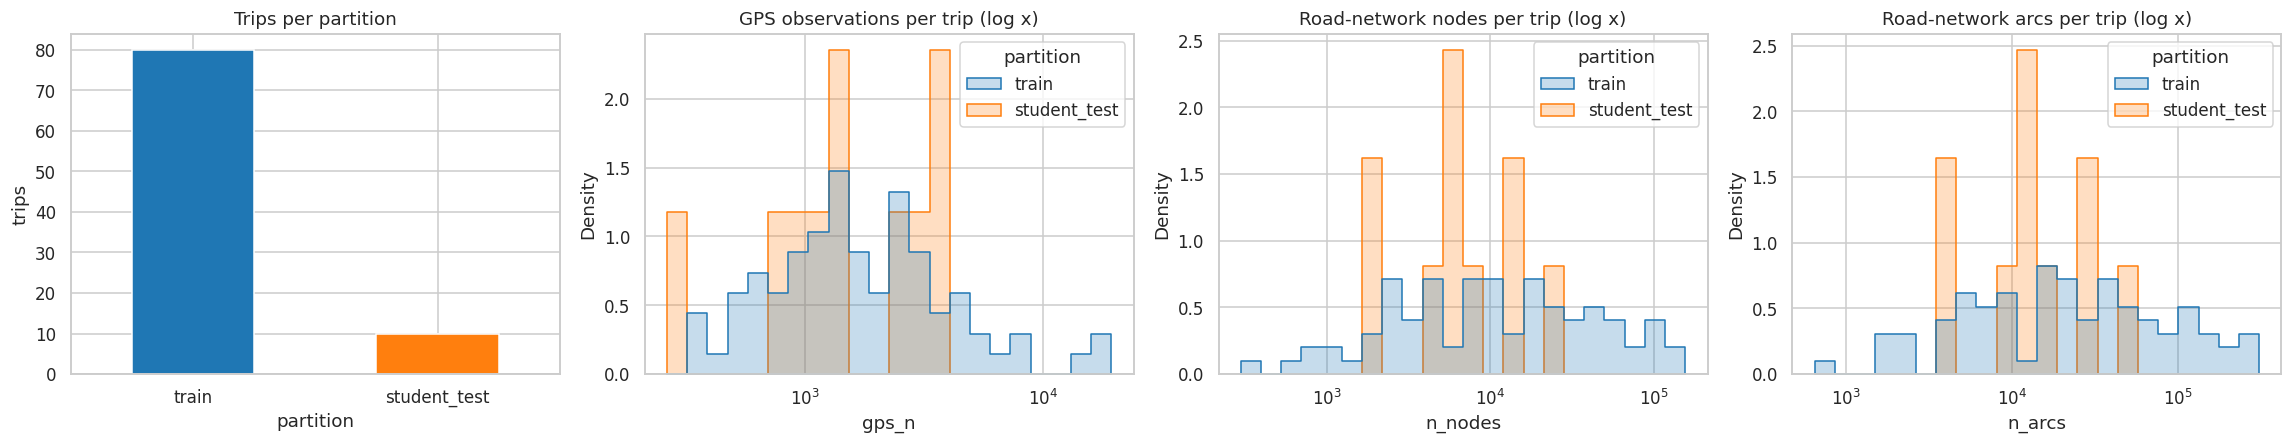

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.2))
S.partition.value_counts().reindex(["train", "student_test"]).plot.bar(ax=ax[0], color=[PAL["train"], PAL["student_test"]], rot=0)
ax[0].set_title("Trips per partition"); ax[0].set_ylabel("trips")
for a, c, ttl in [(ax[1], "gps_n", "GPS observations per trip"), (ax[2], "n_nodes", "Road-network nodes per trip"), (ax[3], "n_arcs", "Road-network arcs per trip")]:
    sns.histplot(data=S, x=c, hue="partition", palette=PAL, log_scale=True, bins=22, element="step", stat="density", common_norm=False, ax=a)
    a.set_title(ttl + " (log x)")
plt.tight_layout(); plt.savefig(f"{FIG}/01_overview.png"); plt.show()

### Where in the world are the trips?
Each trip has its **own road network** and its own location — a model must therefore be location-agnostic (use *relative* features: distances in metres, angles, topology — never raw lon/lat).

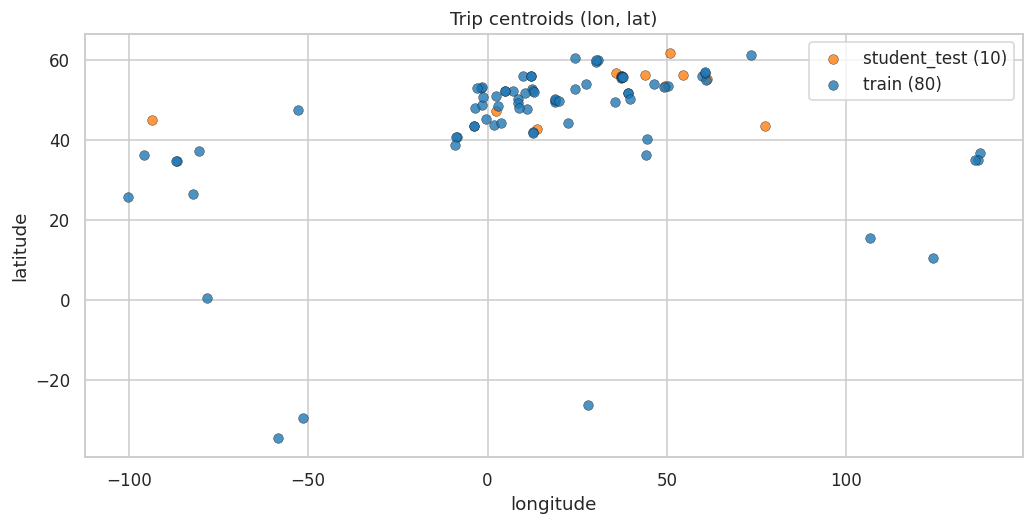

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))
for p, g in S.groupby("partition"):
    ax.scatter(g.lon_c, g.lat_c, s=40, alpha=.8, c=PAL[p], label=f"{p} ({len(g)})", edgecolor="k", linewidth=.3)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("Trip centroids (lon, lat)"); ax.legend()
plt.savefig(f"{FIG}/02_trip_locations.png"); plt.show()

# interactive overview
mo = folium.Map(location=[S.lat_c.median(), S.lon_c.median()], zoom_start=2, tiles="CartoDB positron")
for _, r in S.iterrows():
    folium.CircleMarker([r.lat_c, r.lon_c], radius=5, color=PAL[r.partition], fill=True, fill_opacity=.85,
                        tooltip=f"{r.partition} · trip {r.trip_id} · {int(r.gps_n)} GPS pts").add_to(mo)
mo.save(f"{MAPS}/00_all_trips_overview.html"); mo

## 6. GPS data quality *(missing values, timestamp order, gaps, speeds)*
Checks: NaN / out-of-range / (0,0) coordinates · timestamp ordering and duplicates · irregular time gaps · implausible speeds and jumps · **dwell periods**.

> **Dwell periods.** Many trips contain long stretches where the vehicle is parked or stopped. The GPS then does not stay still — it *jitters inside a blob* (≈ ±10-20 m, steps of ≈ 7 m), so a naive "step < 0.5 m" test finds nothing. We detect a dwell with a **rolling 61-s window whose positional spread (RMS) is < 20 m**. Dwell points are not on any road and have no meaningful reference arc — they matter for labelling and for the candidate miss rate.

In [ ]:
chk = pd.Series({
    "trips with NaN GPS values":              int((S.gps_nan > 0).sum()),
    "trips with out-of-range lon/lat":        int((S.gps_out_of_range > 0).sum()),
    "trips with (0,0) coordinates":           int((S.gps_zero_zero > 0).sum()),
    "trips with non-increasing timestamps (dt<0)":  int((S.dt_neg > 0).sum()),
    "trips with duplicate timestamps (dt==0)":      int((S.dt_zero > 0).sum()),
    "trips with a gap > 5 s":                 int((S.n_gap_gt5 > 0).sum()),
    "trips with a gap > 60 s":                int((S.n_gap_gt60 > 0).sum()),
    "trips with speed > 70 m/s steps":        int((S.n_speed_gt70 > 0).sum()),
    "trips with >100 m jump in 1 s":          int((S.n_jump_gt100m > 0).sum()),
    "trips with >5% of points in a dwell":    int((S.dwell_share > .05).sum()),
    "trips where GPS lies outside network bbox": int((S.gps_in_net_bbox < 1).sum()),
}, name="count (of 90 trips)")
display(chk.to_frame())
pooled_dt1 = (S.pct_dt1 * (S.gps_n - 1)).sum() / (S.gps_n - 1).sum()
pooled_dwell = (S.dwell_share * S.gps_n).sum() / S.gps_n.sum()
print(f"Pooled share of steps with dt == 1 s: {pooled_dt1*100:.2f} %   (the PDF says ~97 %)")
print(f"Pooled share of GPS points inside a dwell (parked/stopped, jitter only): {pooled_dwell*100:.1f} %")
display(S.groupby("partition")[["pct_dt1", "n_gap_gt5", "n_gap_gt60", "dt_max", "gap_time_share", "dwell_share"]].describe().T.round(3))

,count (of 90 trips)
trips with NaN GPS values,0
trips with out-of-range lon/lat,0
"trips with (0,0) coordinates",0
trips with non-increasing timestamps (dt<0),0
trips with duplicate timestamps (dt==0),0
trips with a gap > 5 s,47
trips with a gap > 60 s,23
trips with speed > 70 m/s steps,11
trips with >100 m jump in 1 s,4
trips with >5% of points in a dwell,30


Pooled share of steps with dt == 1 s: 96.68 %   (the PDF says ~97 %)
Pooled share of GPS points inside a dwell (parked/stopped, jitter only): 17.1 %


partition             student_test       train
pct_dt1        count        10.000      80.000
               mean          0.982       0.938
               std           0.043       0.117
               min           0.861       0.531
               25%           0.987       0.959
               50%           0.999       0.991
               75%           1.000       1.000
               max           1.000       1.000
n_gap_gt5      count        10.000      80.000
               mean          4.400      15.200
               std          12.258      42.351
               min           0.000       0.000
               25%           0.000       0.000
               50%           0.000       1.000
               75%           0.000      11.250
               max          39.000     320.000
n_gap_gt60     count        10.000      80.000
               mean          0.100       0.862
               std           0.316       2.633
               min           0.000       0.000
               25%           0.000       0.000
               50%           0.000       0.000
               75%           0.000       1.000
               max           1.000      17.000
dt_max         count        10.000      80.000
               mean         25.500    2706.400
               std          65.529   18017.445
               min           1.000       1.000
               25%           1.000       1.750
               50%           2.000      11.000
               75%           2.750      73.750
               max         210.000  153064.000
gap_time_share count        10.000      80.000
               mean          0.076       0.193
               std           0.152       0.261
               min           0.000       0.000
               25%           0.000       0.000
               50%           0.001       0.080
               75%           0.028       0.283
               max           0.436       0.998
dwell_share    count        10.000      80.000
               mean          0.053       0.078
               std           0.101       0.158
               min           0.000       0.000
               25%           0.000       0.000
               50%           0.004       0.006
               75%           0.043       0.092
               max           0.317       0.866

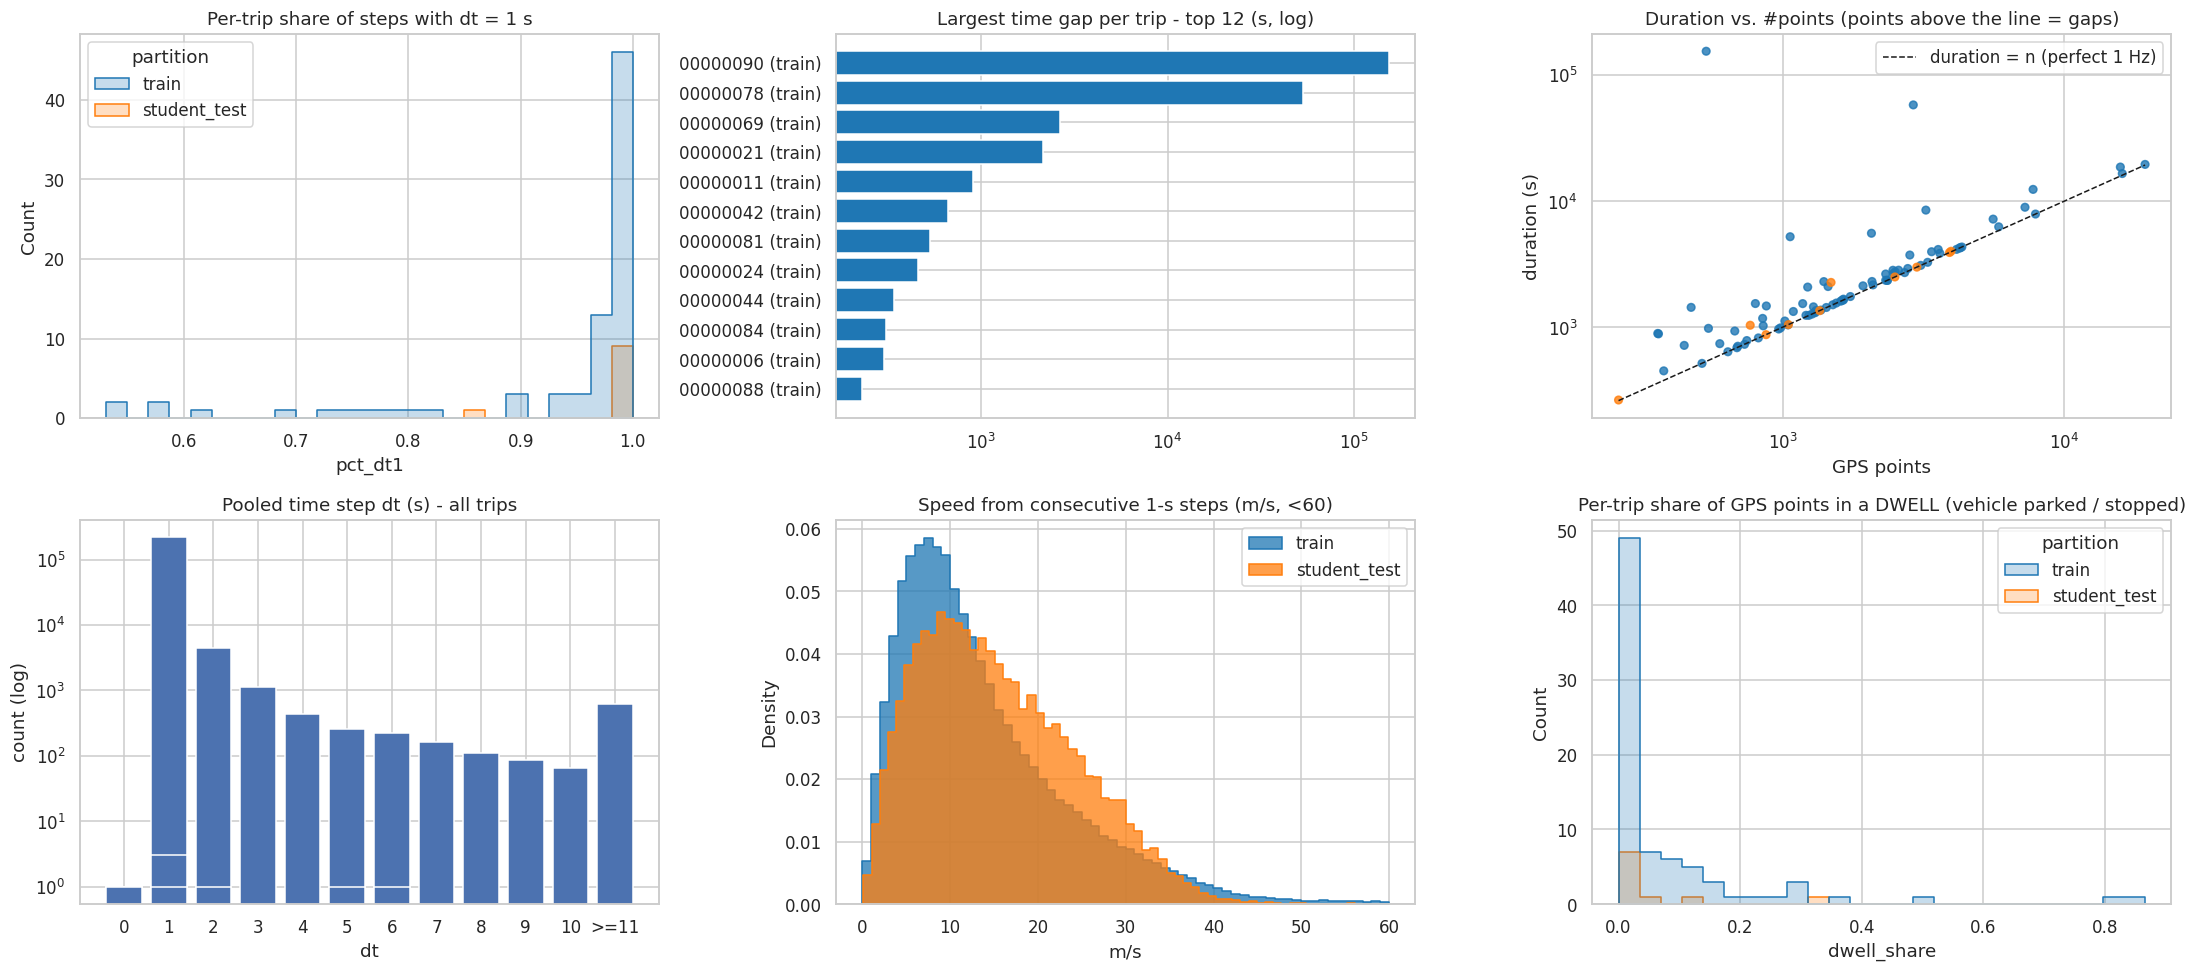

Speed quantiles on 1-s steps (m/s): {'train': [11.2, 27.7, 46.7, 67.3, 180.2], 'student_test': [14.2, 28.1, 37.3, 46.2, 72.9]}   (quantiles: 50/90/99/99.9/max)


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(20, 9))
sns.histplot(data=S, x="pct_dt1", hue="partition", palette=PAL, bins=25, element="step", ax=ax[0, 0]); ax[0, 0].set_title("Per-trip share of steps with dt = 1 s")
big = S.sort_values("dt_max", ascending=False).head(12)
ax[0, 1].barh(big.trip_id + " (" + big.partition.str[:5] + ")", big.dt_max, color=[PAL[p] for p in big.partition]); ax[0, 1].set_xscale("log"); ax[0, 1].invert_yaxis()
ax[0, 1].set_title("Largest time gap per trip - top 12 (s, log)")
ax[0, 2].scatter(S.gps_n, S.duration_s, c=[PAL[p] for p in S.partition], s=25, alpha=.8); ax[0, 2].set_xscale("log"); ax[0, 2].set_yscale("log")
ax[0, 2].plot([S.gps_n.min(), S.gps_n.max()], [S.gps_n.min(), S.gps_n.max()], "k--", lw=1, label="duration = n (perfect 1 Hz)")
ax[0, 2].set_xlabel("GPS points"); ax[0, 2].set_ylabel("duration (s)"); ax[0, 2].set_title("Duration vs. #points (points above the line = gaps)"); ax[0, 2].legend()

all_dt = np.concatenate([np.diff(load_trip(p, t)["track"][:, 2]) for p, t in jobs])
vc = pd.Series(all_dt).clip(upper=11).value_counts().sort_index()
ax[1, 0].bar(vc.index.astype(int).astype(str).str.replace("11", ">=11"), vc.values, color="#4c72b0"); ax[1, 0].set_yscale("log")
ax[1, 0].set_title("Pooled time step dt (s) - all trips"); ax[1, 0].set_xlabel("dt"); ax[1, 0].set_ylabel("count (log)")

sp = {p: np.concatenate([v for (pp, _), v in SPEED.items() if pp == p]) for p in PARTS}
for p, v in sp.items(): sns.histplot(v[v < 60], bins=60, stat="density", element="step", color=PAL[p], label=p, ax=ax[1, 1])
ax[1, 1].set_title("Speed from consecutive 1-s steps (m/s, <60)"); ax[1, 1].set_xlabel("m/s"); ax[1, 1].legend()
sns.histplot(data=S, x="dwell_share", hue="partition", palette=PAL, bins=25, element="step", ax=ax[1, 2]); ax[1, 2].set_title("Per-trip share of GPS points in a DWELL (vehicle parked / stopped)")
plt.tight_layout(); plt.savefig(f"{FIG}/03_gps_quality.png"); plt.show()
print("Speed quantiles on 1-s steps (m/s):", {p: np.percentile(v, [50, 90, 99, 99.9, 100]).round(1).tolist() for p, v in sp.items()}, "  (quantiles: 50/90/99/99.9/max)")

## 7. Road network *(size, connectivity, isolated nodes, disconnected components)*
Connected components are computed on the **undirected** graph (weak connectivity) with `scipy.sparse.csgraph`. The Viterbi transition model will have to respect these facts: segments in different components can never be connected.

In [ ]:
ncols = ["n_nodes", "n_arcs", "mean_out_degree", "components", "largest_comp_share", "isolated_nodes", "self_loops", "dup_arcs",
         "oneway_share", "arc_len_median_m", "arc_len_max_m", "net_len_km", "net_w_km", "net_h_km"]
display(S.groupby("partition")[ncols].median().round(3).T.rename(columns=lambda c: f"median ({c})"))
print("Arc ids / node ids valid in every trip:", bool(S.arcs_valid.all()))
print("Trips with isolated nodes:", int((S.isolated_nodes > 0).sum()), "| trips with self-loops:", int((S.self_loops > 0).sum()),
      "| trips with duplicate arcs:", int((S.dup_arcs > 0).sum()))
print("Trips whose largest component holds <90% of nodes:", int((S.largest_comp_share < .9).sum()))

partition,median (student_test),median (train)
n_nodes,6596.500,9608.000
n_arcs,13145.000,19526.500
mean_out_degree,2.066,2.030
components,11.000,20.000
largest_comp_share,0.971,0.981
isolated_nodes,0.000,0.000
self_loops,0.000,0.000
dup_arcs,3.500,2.000
oneway_share,0.067,0.049
arc_len_median_m,31.866,24.550


Arc ids / node ids valid in every trip: True
Trips with isolated nodes: 0 | trips with self-loops: 9 | trips with duplicate arcs: 60
Trips whose largest component holds <90% of nodes: 3


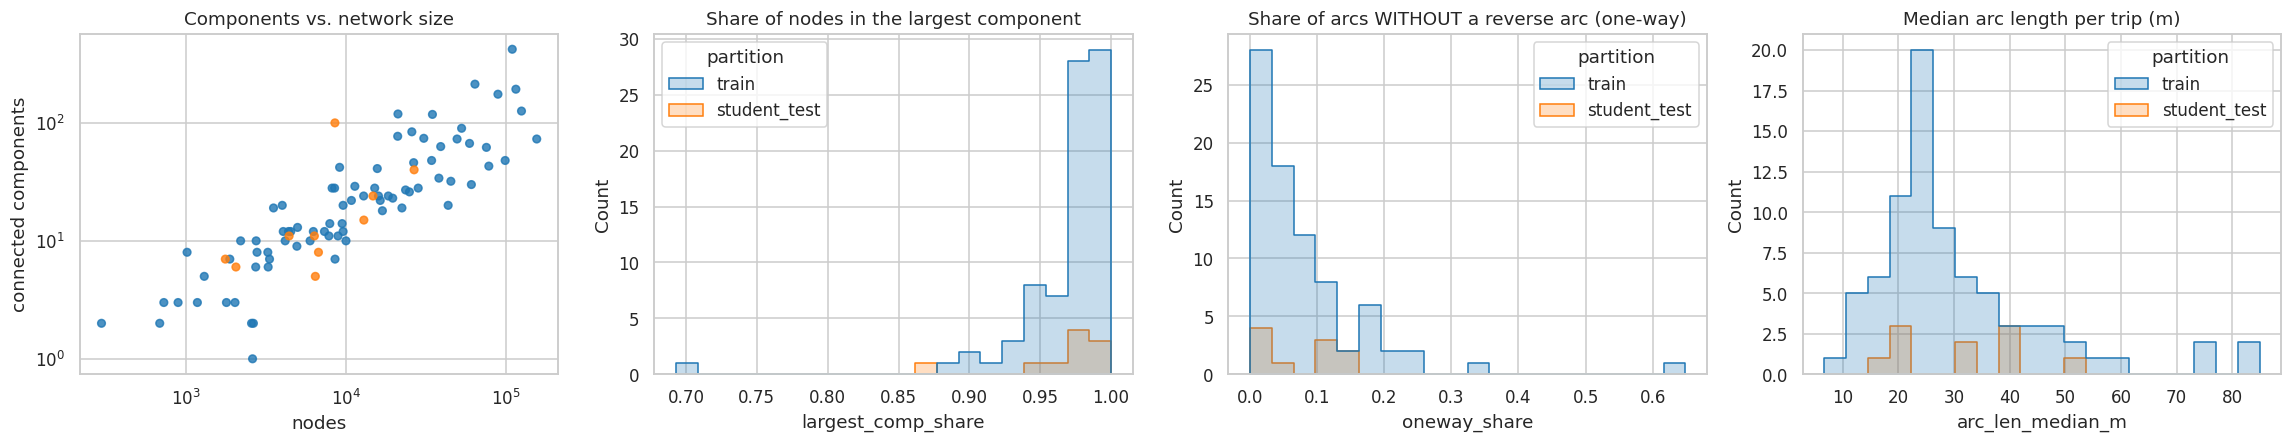

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.2))
ax[0].scatter(S.n_nodes, S.components, c=[PAL[p] for p in S.partition], s=25, alpha=.8); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("nodes"); ax[0].set_ylabel("connected components"); ax[0].set_title("Components vs. network size")
sns.histplot(data=S, x="largest_comp_share", hue="partition", palette=PAL, bins=20, element="step", ax=ax[1]); ax[1].set_title("Share of nodes in the largest component")
sns.histplot(data=S, x="oneway_share", hue="partition", palette=PAL, bins=20, element="step", ax=ax[2]); ax[2].set_title("Share of arcs WITHOUT a reverse arc (one-way)")
sns.histplot(data=S, x="arc_len_median_m", hue="partition", palette=PAL, bins=20, element="step", ax=ax[3]); ax[3].set_title("Median arc length per trip (m)")
plt.tight_layout(); plt.savefig(f"{FIG}/04_network.png"); plt.show()

## 8. Reference route *(encoding, validity, continuity)*
`.route` = ordered **arc ids**. We verify (a) every id exists, (b) consecutive arcs are connected (`to_node[i] == from_node[i+1]`), (c) arcs are re-used, (d) the route lies in the largest connected component, and (e) how many GPS points there are per route arc.

> The PDF warns that the reference route is *reference information*, not independently verified truth — so we also look for anomalies instead of assuming it is perfect.

Route ids valid in every trip: True


partition                 student_test     train
route_n            count        10.000    80.000
                   mean        347.700   391.700
                   std         359.574   361.165
                   min          95.000    59.000
                   25%         153.500   168.250
                   50%         250.000   280.000
                   75%         357.750   480.500
                   max        1323.000  2266.000
route_len_km       count        10.000    80.000
                   mean         24.763    27.827
                   std          21.226    25.688
                   min           5.281     5.005
                   25%           9.861     8.909
                   50%          14.733    14.296
                   75%          40.183    39.384
                   max          64.754    94.146
gps_per_route_arc  count        10.000    80.000
                   mean          7.051     8.276
                   std           4.796     9.386
                   min           2.445     1.261
                   25%           3.186     3.316
                   50%           4.635     5.289
                   75%          10.679     8.434
                   max          14.593    56.978
route_cont         count        10.000    80.000
                   mean          1.000     0.999
                   std           0.001     0.002
                   min           0.997     0.981
                   25%           1.000     1.000
                   50%           1.000     1.000
                   75%           1.000     1.000
                   max           1.000     1.000
route_breaks       count        10.000    80.000
                   mean          0.100     0.162
                   std           0.316     0.489
                   min           0.000     0.000
                   25%           0.000     0.000
                   50%           0.000     0.000
                   75%           0.000     0.000
                   max           1.000     3.000
route_repeat_share count        10.000    80.000
                   mean          0.019     0.002
                   std           0.061     0.010
                   min           0.000     0.000
                   25%           0.000     0.000
                   50%           0.000     0.000
                   75%           0.000     0.000
                   max           0.193     0.062
route_in_big_comp  count        10.000    80.000
                   mean          1.000     1.000
                   std           0.000     0.000
                   min           1.000     1.000
                   25%           1.000     1.000
                   50%           1.000     1.000
                   75%           1.000     1.000
                   max           1.000     1.000

Trips with a discontinuity in the route: 11  | total broken links: 14 of 34813 route transitions
Trips whose route is not fully inside the largest component: 0


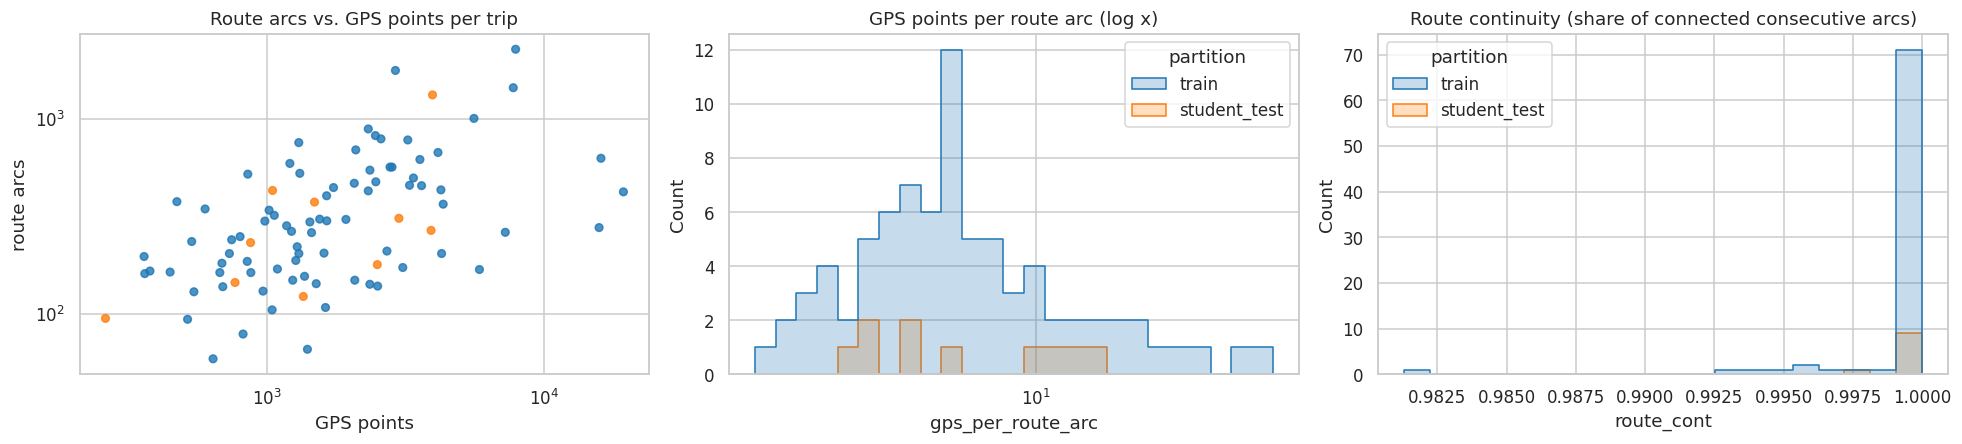

In [ ]:
print("Route ids valid in every trip:", bool(S.route_valid.all()))
display(S.groupby("partition")[["route_n", "route_len_km", "gps_per_route_arc", "route_cont", "route_breaks", "route_repeat_share", "route_in_big_comp"]].describe().T.round(3))
print(f"Trips with a discontinuity in the route: {int((S.route_breaks > 0).sum())}  | total broken links: {int(S.route_breaks.sum())} of {int(S.route_n.sum())} route transitions")
print(f"Trips whose route is not fully inside the largest component: {int((S.route_in_big_comp < 1).sum())}")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
ax[0].scatter(S.gps_n, S.route_n, c=[PAL[p] for p in S.partition], s=25, alpha=.8); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("GPS points"); ax[0].set_ylabel("route arcs"); ax[0].set_title("Route arcs vs. GPS points per trip")
sns.histplot(data=S, x="gps_per_route_arc", hue="partition", palette=PAL, bins=25, element="step", log_scale=True, ax=ax[1]); ax[1].set_title("GPS points per route arc (log x)")
sns.histplot(data=S, x="route_cont", hue="partition", palette=PAL, bins=20, element="step", ax=ax[2]); ax[2].set_title("Route continuity (share of connected consecutive arcs)")
plt.tight_layout(); plt.savefig(f"{FIG}/05_route.png"); plt.show()

## 9. GPS noise & candidate-radius evidence
Distance from each GPS point to the reference route is the best available measure of **how far GPS strays from the true road**. It answers a key modelling question:

> *How large must the candidate-search radius be so that the true road segment is (almost always) inside the candidate set — without producing huge candidate sets?*

That trade-off is exactly the **Candidate Miss Rate** metric from the Models guide. `recall(R)` = share of GPS points whose reference route lies within `R` metres (an upper bound on 1 − miss-rate for a radius-based generator); the average number of network **nodes** within `R` is a proxy for candidate-set size.

**Important:** we report recall for *all points* **and** for *moving points only* (dwell points removed), because parked-vehicle jitter is far from any road and would otherwise inflate the "required radius". We also look at **off-route stretches** (long consecutive runs of points > 100 m from the route).  
*The radius is chosen on `train` only; `student_test` just checks it.*

Distance GPS -> reference route (m), pooled over GPS points:


,train / all,train / moving,student_test / all,student_test / moving
p50,5.6,4.8,5.2,5.0
p75,10.8,8.4,8.9,8.6
p90,74.9,12.8,13.4,12.5
p95,140.2,16.9,16.8,15.2
p99,203.3,61.7,27.9,22.2
p99.9,335.5,364.5,71.6,74.1
p100,569.5,545.9,106.0,106.0


Candidate recall by radius:


,train / all,train / moving,student_test / all,student_test / moving
radius_m,,,,
10,0.7252,0.8211,0.7986,0.8178
20,0.8589,0.9651,0.9719,0.9846
30,0.8782,0.9821,0.9926,0.9962
50,0.8918,0.9886,0.9986,0.9985
75,0.9000,0.9912,0.9992,0.9991
100,0.9041,0.9932,0.9998,0.9998
150,0.9579,0.9963,1.0000,1.0000
200,0.9891,0.9981,1.0000,1.0000


Smallest radius with train moving-point recall >= 99.0%: 65 m  |  student_test recall there: moving 99.87%, all points 99.88%
Smallest radius with train moving-point recall >= 99.5%: 135 m  |  student_test recall there: moving 100.00%, all points 100.00%

Trips whose moving-point recall at R=65 m is still < 95%  (need adaptive/k-nearest candidates or special handling): [('train', '00000002', 0.918), ('train', '00000043', 0.936), ('train', '00000054', 0.743)]


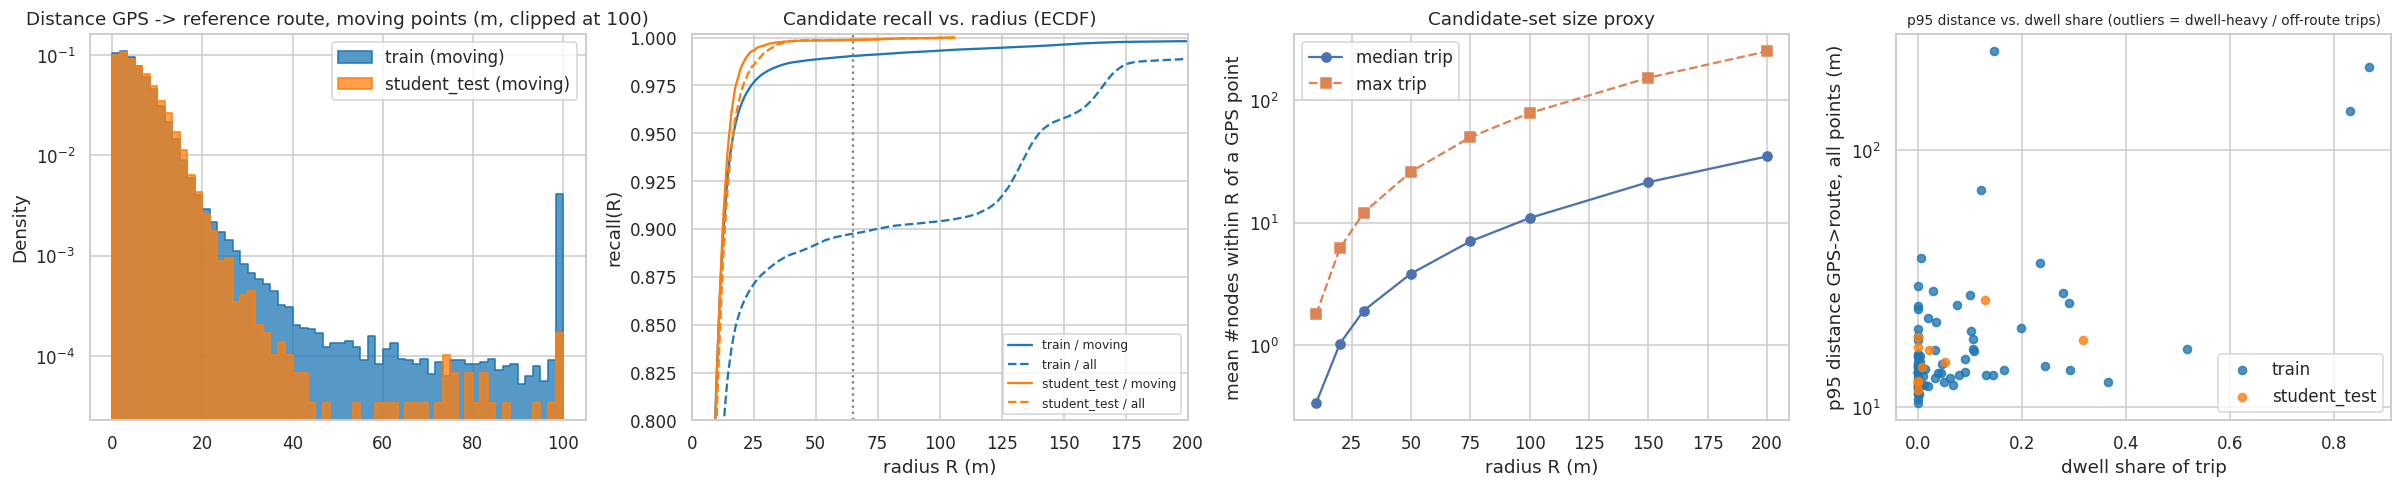


Off-route stretches (runs of consecutive points > 100 m from the route) - top 8 trips by longest run:


,partition,trip_id,gps_n,dwell_share,far_share,n_far_runs,longest_far_run,d_route_p50,d_route_p95_moving
0,train,00000054,19313,0.866,0.836,50,3218,138.514,157.619
1,train,00000033,5844,0.831,0.510,2,2977,122.383,63.434
2,train,00000002,7243,0.146,0.099,5,513,5.688,251.206
3,train,00000043,2322,0.121,0.026,3,58,10.996,76.619
4,train,00000020,2353,0.000,0.008,1,18,5.459,24.055
5,train,00000019,2354,0.089,0.009,3,14,5.530,15.516
6,train,00000028,3565,0.000,0.003,1,12,6.135,20.067
7,train,00000081,3224,0.005,0.004,5,8,4.436,38.151


In [ ]:
def pool_of(p, moving):
    return np.concatenate([(DIST[k][~DWELL[k]] if moving else DIST[k]) for k in DIST if k[0] == p])
pool_all = {p: pool_of(p, False) for p in PARTS}
pool_mv  = {p: pool_of(p, True)  for p in PARTS}

q = [50, 75, 90, 95, 99, 99.9, 100]
pctl = pd.DataFrame({f"{p} / {lab}": np.percentile(pl[p], q) for p in PARTS for lab, pl in (("all", pool_all), ("moving", pool_mv))},
                    index=[f"p{x}" for x in q]).round(1)
print("Distance GPS -> reference route (m), pooled over GPS points:"); display(pctl)
rec = pd.DataFrame({f"{p} / {lab}": [(pl[p] <= R).mean() for R in RADII] for p in PARTS for lab, pl in (("all", pool_all), ("moving", pool_mv))},
                   index=pd.Index(RADII, name="radius_m")).round(4)
print("Candidate recall by radius:"); display(rec)

# radius recommendation: smallest R on a fine grid with train MOVING-point recall >= target  (train only!)
fine = np.arange(5, 301, 5)
def r_for(target): return next((R for R in fine if (pool_mv["train"] <= R).mean() >= target), None)
R99, R995 = r_for(.99), r_for(.995)
for tgt, R in ((.99, R99), (.995, R995)):
    print(f"Smallest radius with train moving-point recall >= {tgt*100:.1f}%: {R} m  |  student_test recall there: moving {(pool_mv['student_test']<=R).mean()*100:.2f}%, all points {(pool_all['student_test']<=R).mean()*100:.2f}%")
bad = [(k[0], k[1], round(float((DIST[k][~DWELL[k]] <= R99).mean()), 3)) for k in DIST if (DIST[k][~DWELL[k]] <= R99).mean() < .95]
print(f"\nTrips whose moving-point recall at R={R99} m is still < 95%  (need adaptive/k-nearest candidates or special handling): {bad}")

fig, ax = plt.subplots(1, 4, figsize=(22, 4.6))
for p in PARTS: sns.histplot(np.clip(pool_mv[p], 0, 100), bins=60, stat="density", element="step", color=PAL[p], label=f"{p} (moving)", ax=ax[0])
ax[0].set_title("Distance GPS -> reference route, moving points (m, clipped at 100)"); ax[0].set_yscale("log"); ax[0].legend()
for p in PARTS:
    for pl, ls, lab in ((pool_mv, "-", "moving"), (pool_all, "--", "all")):
        xs = np.sort(pl[p]); ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), ls, color=PAL[p], label=f"{p} / {lab}")
ax[1].set_xlim(0, 200); ax[1].set_ylim(.8, 1.002); ax[1].set_xlabel("radius R (m)"); ax[1].set_ylabel("recall(R)"); ax[1].set_title("Candidate recall vs. radius (ECDF)"); ax[1].legend(fontsize=8)
if R99: ax[1].axvline(R99, ls=":", c="gray")
nodes_cols = [f"nodes_in_{R}" for R in RADII]
ax[2].plot(RADII, S[nodes_cols].median().values, "o-", label="median trip"); ax[2].plot(RADII, S[nodes_cols].max().values, "s--", label="max trip")
ax[2].set_xlabel("radius R (m)"); ax[2].set_ylabel("mean #nodes within R of a GPS point"); ax[2].set_title("Candidate-set size proxy"); ax[2].set_yscale("log"); ax[2].legend()
for p in PARTS: ax[3].scatter(S[S.partition == p].dwell_share, S[S.partition == p].d_route_p95, s=28, c=PAL[p], alpha=.8, label=p)
ax[3].set_yscale("log"); ax[3].set_xlabel("dwell share of trip"); ax[3].set_ylabel("p95 distance GPS->route, all points (m)"); ax[3].set_title("p95 distance vs. dwell share (outliers = dwell-heavy / off-route trips)", fontsize=9); ax[3].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/06_gps_noise_candidate_radius.png"); plt.show()

print("\nOff-route stretches (runs of consecutive points > 100 m from the route) - top 8 trips by longest run:")
display(S.sort_values("longest_far_run", ascending=False).head(8)[["partition", "trip_id", "gps_n", "dwell_share", "far_share", "n_far_runs", "longest_far_run", "d_route_p50", "d_route_p95_moving"]].round(3).reset_index(drop=True))

## 10. Trips with anomalies
A rule-based flag table (thresholds are visible and editable in `TH`). Use it to decide which trips need special handling (gap logic in the HMM, outlier-robust features, etc.) — and which ones to show on a map in the report.

In [ ]:
TH = dict(gap_s=60, pct_dt1_min=0.90, comp_share_min=0.90, d_p95_max=50, far_run=100, dwell_max=0.30)
def flag_row(r):
    f = []
    if r.gps_nan or r.gps_out_of_range or r.gps_zero_zero: f.append("invalid GPS values")
    if r.dt_neg or r.dt_zero: f.append("non-increasing timestamps")
    if r.dt_max > TH["gap_s"]: f.append(f"GPS gap {r.dt_max:.0f}s")
    if r.pct_dt1 < TH["pct_dt1_min"]: f.append(f"irregular sampling ({r.pct_dt1*100:.0f}% dt=1)")
    if r.n_speed_gt70 or r.n_jump_gt100m: f.append("speed/jump outliers")
    if r.largest_comp_share < TH["comp_share_min"]: f.append(f"fragmented network ({r.largest_comp_share*100:.0f}% in main comp.)")
    if r.route_breaks > 0: f.append(f"{int(r.route_breaks)} route break(s)")
    if r.route_in_big_comp < 1: f.append("route leaves main component")
    if r.d_route_p95_moving > TH["d_p95_max"]: f.append(f"noisy GPS while moving (p95={r.d_route_p95_moving:.0f} m)")
    if r.longest_far_run >= TH["far_run"]: f.append(f"off-route stretch of {int(r.longest_far_run)} pts (>100 m from route)")
    if r.dwell_share > TH["dwell_max"]: f.append(f"long dwell ({r.dwell_share*100:.0f}% of points parked)")
    return "; ".join(f)
S["flags"] = S.apply(flag_row, axis=1)
fl = S[S["flags"] != ""][["partition", "trip_id", "gps_n", "flags"]]
print(f"{len(fl)} of {len(S)} trips have at least one flag"); display(fl.reset_index(drop=True))

53 of 90 trips have at least one flag


,partition,trip_id,gps_n,flags
0,train,00000001,1315,speed/jump outliers
1,train,00000002,7243,GPS gap 160s; 1 route break(s); noisy GPS whil...
2,train,00000004,1064,irregular sampling (54% dt=1)
3,train,00000006,1450,GPS gap 301s
4,train,00000008,3093,speed/jump outliers
5,train,00000010,2711,long dwell (52% of points parked)
6,train,00000011,2828,GPS gap 909s
7,train,00000013,2580,speed/jump outliers
8,train,00000014,448,GPS gap 72s; irregular sampling (82% dt=1)
9,train,00000018,379,irregular sampling (90% dt=1)


## 11. Visualising trips (static + interactive Folium) *(mandatory deliverable)*
`trip_map()` writes an interactive Folium map with toggleable layers: **GPS observations** (blue), **GPS path**, **road network** (grey), **reference route** (green), **GPS gaps** (dashed red) and **start/end** markers, plus a legend. Open the saved HTML files for the report screenshots.

We auto-pick representative trips: smallest / median / largest train trip, the trip with the largest GPS gap, the most fragmented network, the noisiest trip (while moving), a dwell-heavy trip, and one `student_test` trip. The static grid skips the very large trip to stay readable. Override with `PICK = {...}` if you prefer others.

In [ ]:
def pick_trips():
    tr = S[S.partition == "train"].sort_values("gps_n").reset_index(drop=True)
    te = S[S.partition == "student_test"].sort_values("gps_n").reset_index(drop=True)
    pk = {
        "smallest_train":  ("train", tr.trip_id.iloc[0]),
        "median_train":    ("train", tr.trip_id.iloc[len(tr) // 2]),
        "largest_train":   ("train", tr.trip_id.iloc[-1]),
        "largest_gap":     tuple(S.loc[S.dt_max.idxmax(), ["partition", "trip_id"]]),
        "most_fragmented": tuple(S.loc[S.largest_comp_share.idxmin(), ["partition", "trip_id"]]),
        "noisiest_gps":    tuple(S.loc[S.d_route_p95_moving.idxmax(), ["partition", "trip_id"]]),
        "dwell_heavy":     tuple(S[S.gps_n < 8000].loc[S[S.gps_n < 8000].dwell_share.idxmax(), ["partition", "trip_id"]]),
        "median_student_test": ("student_test", te.trip_id.iloc[len(te) // 2]),
    }
    return pk
PICK = pick_trips()          # <- override here if needed, e.g. {"demo": ("train", "00000005")}
display(pd.DataFrame([(k, *v) for k, v in PICK.items()], columns=["why", "partition", "trip_id"]).merge(
    S[["partition", "trip_id", "gps_n", "n_nodes", "n_arcs", "route_n", "dt_max", "largest_comp_share", "d_route_p95_moving", "dwell_share"]], on=["partition", "trip_id"]))

,why,partition,trip_id,gps_n,n_nodes,n_arcs,route_n,dt_max,largest_comp_share,d_route_p95_moving,dwell_share
0,smallest_train,train,00000026,361,2580,5043,197,17.0,0.958140,14.197457,0.000000
1,median_train,train,00000095,1551,1888,3723,306,2.0,0.692797,12.243669,0.003868
2,largest_train,train,00000054,19313,63822,116916,422,79.0,0.970371,157.619262,0.866411
3,largest_gap,train,00000090,536,4010,7942,235,153064.0,0.940898,12.791484,0.000000
4,most_fragmented,train,00000095,1551,1888,3723,306,2.0,0.692797,12.243669,0.003868
5,noisiest_gps,train,00000002,7243,7936,16139,262,160.0,0.976562,251.206428,0.145796
6,dwell_heavy,train,00000033,5844,3340,6360,169,3.0,0.985928,63.433778,0.830938
7,median_student_test,student_test,00000076,1486,26635,56027,374,32.0,0.962230,18.664168,0.000000


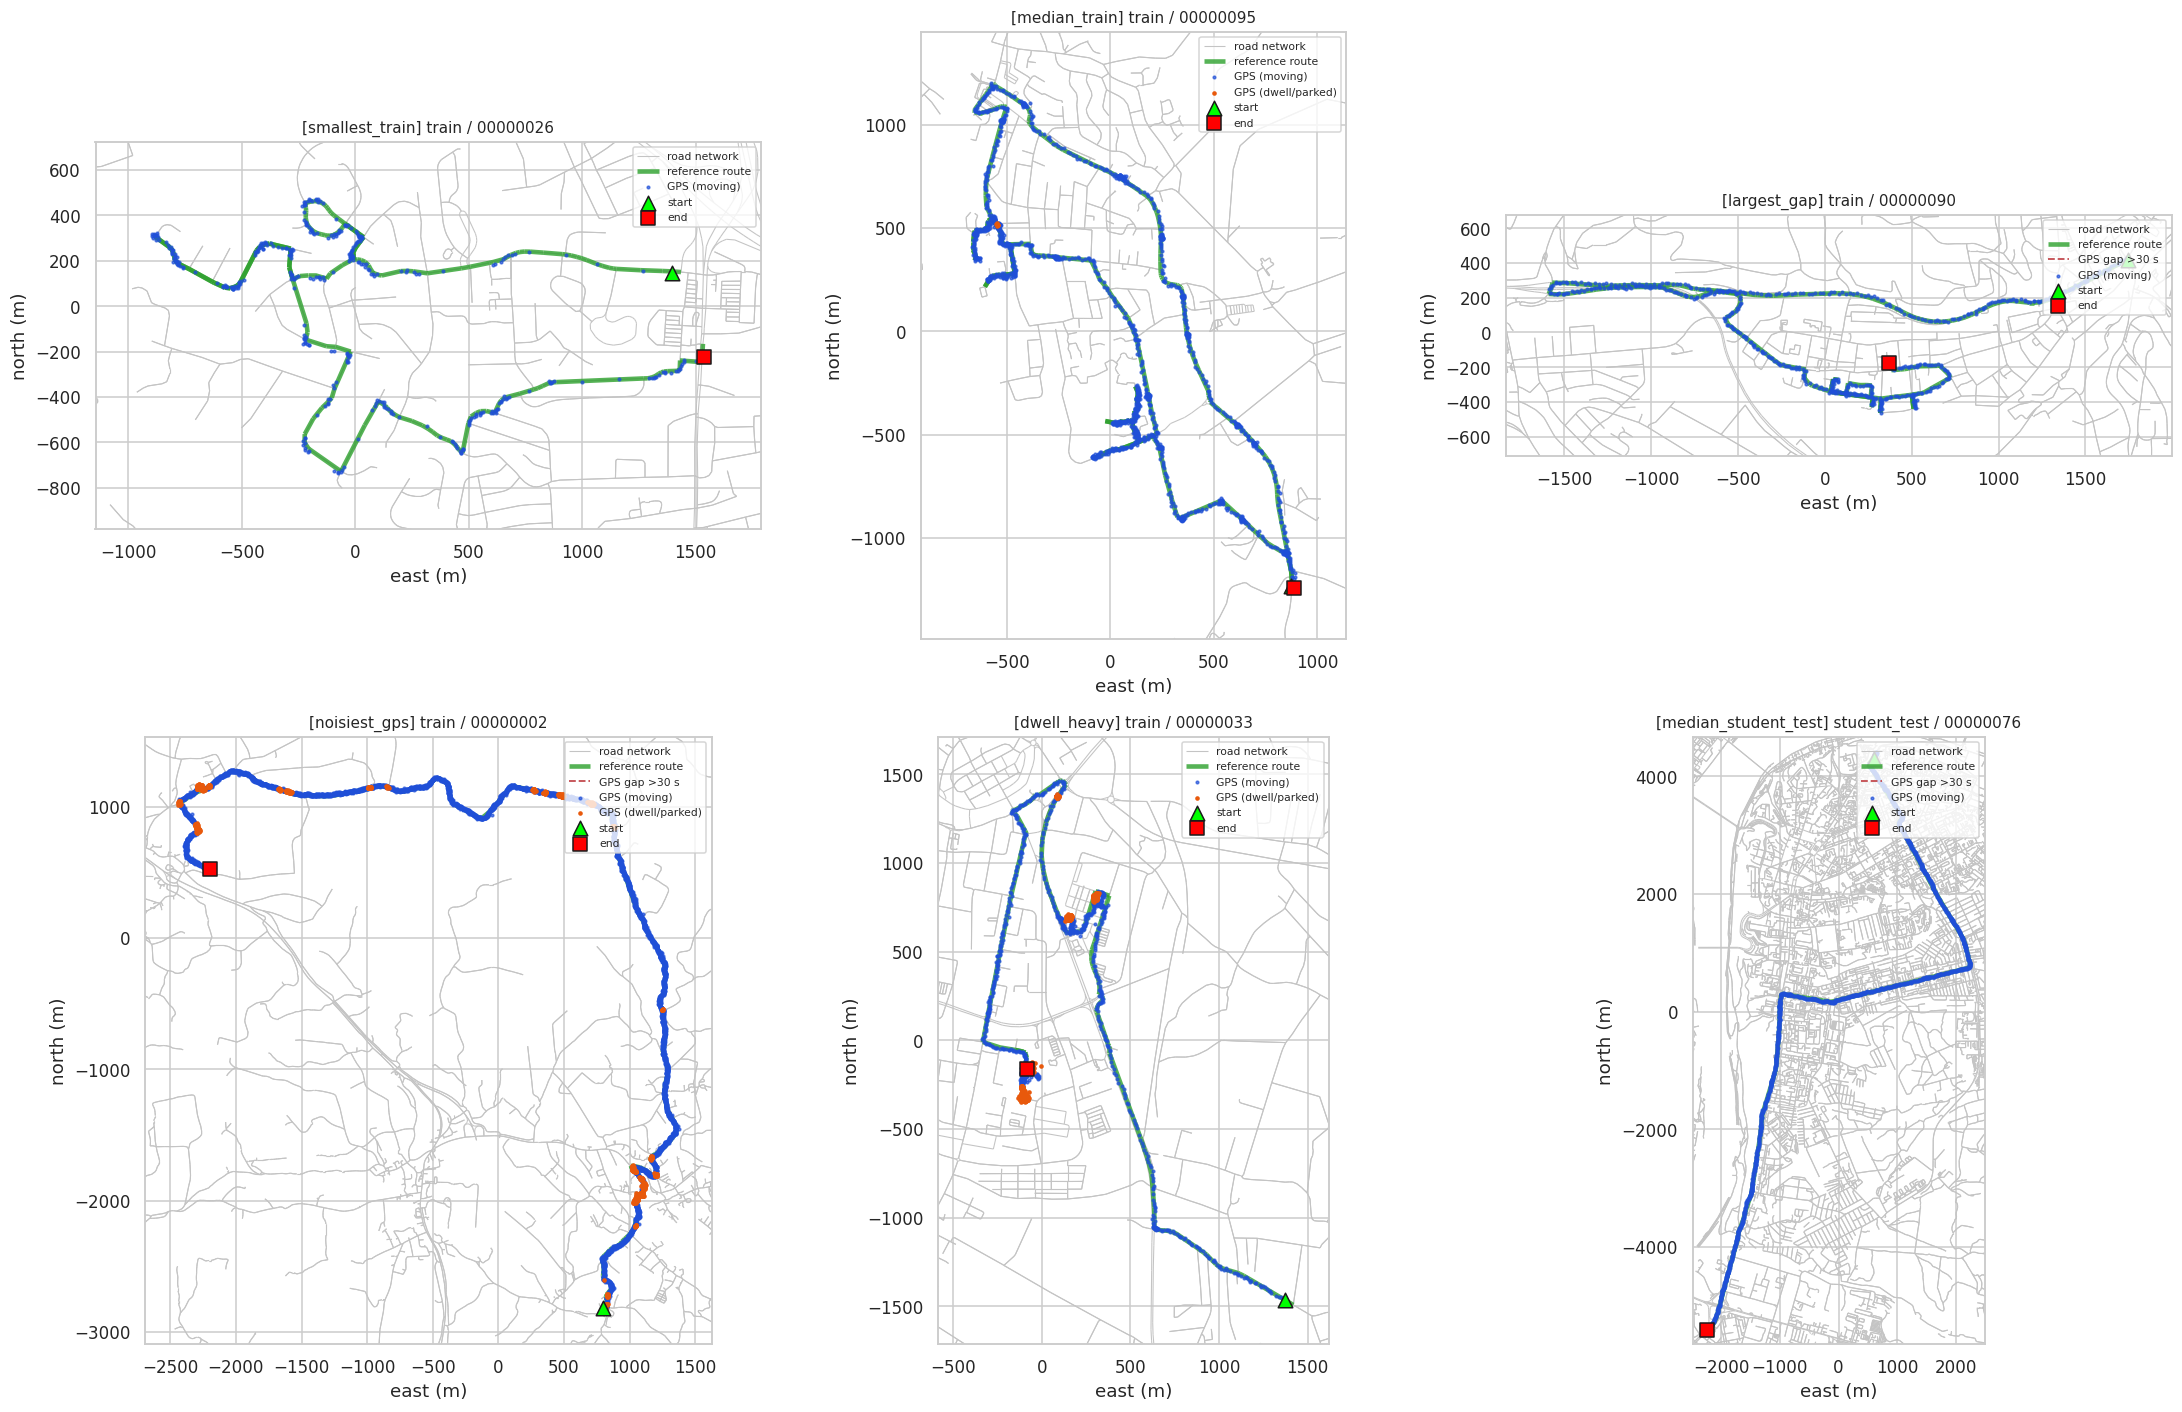

In [ ]:
def _window(xy, buf):
    return xy[:, 0].min() - buf, xy[:, 0].max() + buf, xy[:, 1].min() - buf, xy[:, 1].max() + buf

def plot_trip_static(part, tid, buffer_m=250, ax=None):
    """Matplotlib view in local metres: network (grey), reference route (green), GPS (blue), gaps (red dashed)."""
    T = load_trip(part, tid); trk, nodes, arcs, route = T["track"], T["nodes"], T["arcs"], T["route"]
    proj = make_proj(trk[:, 0].mean(), trk[:, 1].mean()); xy = proj(trk[:, 0], trk[:, 1]); nxy = proj(nodes[:, 0], nodes[:, 1])
    x0, x1, y0, y1 = _window(xy, buffer_m)
    inwin = lambda p: (p[:, 0] >= x0) & (p[:, 0] <= x1) & (p[:, 1] >= y0) & (p[:, 1] <= y1)
    m = inwin(nxy[arcs[:, 0]]) | inwin(nxy[arcs[:, 1]])
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(8, 8))
    ax.add_collection(LineCollection(np.stack([nxy[arcs[m, 0]], nxy[arcs[m, 1]]], 1), colors="#c4c4c4", linewidths=.7, label="road network"))
    ax.add_collection(LineCollection(np.stack([nxy[arcs[route, 0]], nxy[arcs[route, 1]]], 1), colors="#2ca02c", linewidths=3, alpha=.8, label="reference route"))
    dt = np.diff(trk[:, 2]); gi = np.where(dt > 30)[0]
    for i in gi: ax.plot(xy[i:i + 2, 0], xy[i:i + 2, 1], "r--", lw=1.2, label="GPS gap >30 s" if i == gi[0] else None)
    dm = dwell_mask(xy)
    ax.scatter(xy[~dm, 0], xy[~dm, 1], s=3, c="#1f4fd8", alpha=.7, label="GPS (moving)", zorder=3)
    if dm.any(): ax.scatter(xy[dm, 0], xy[dm, 1], s=4, c="#e8590c", label="GPS (dwell/parked)", zorder=3)
    ax.scatter(*xy[0], marker="^", s=90, c="lime", edgecolor="k", zorder=5, label="start"); ax.scatter(*xy[-1], marker="s", s=80, c="red", edgecolor="k", zorder=5, label="end")
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("equal"); ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)")
    ax.set_title(f"{part} / trip {tid}  ({len(trk)} GPS pts)", fontsize=10); ax.legend(loc="upper right", fontsize=7)
    if own: plt.savefig(f"{FIG}/trip_{part}_{tid}.png"); plt.show()

fig, axs = plt.subplots(2, 3, figsize=(20, 13))
_seen, _grid = set(), []
for k, v in PICK.items():
    if k != "largest_train" and v not in _seen: _seen.add(v); _grid.append((k, v))
for a, (k, (p, t)) in zip(axs.ravel(), _grid[:6]):
    plot_trip_static(p, t, ax=a); a.set_title(f"[{k}] {p} / {t}", fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIG}/07_example_trips.png"); plt.show()

In [ ]:
LEGEND_HTML = """
<div style="position: fixed; bottom: 28px; left: 28px; z-index: 9999; background: white; padding: 10px 12px;
            border: 2px solid #888; border-radius: 6px; font-size: 13px; line-height: 1.5;">
<b>Legend</b><br>
<span style="color:#1f4fd8;">&#9679;</span> GPS observations (moving)<br>
<span style="color:#e8590c;">&#9679;</span> GPS observations (dwell / parked)<br>
<span style="color:#7fa6ff;">&#9644;</span> GPS path (in time order)<br>
<span style="color:#999;">&#9644;</span> Road network (arcs)<br>
<span style="color:#2ca02c;">&#9644;</span> Reference route<br>
<span style="color:red;">- - -</span> GPS gap &gt; 30 s<br>
<span style="color:green;">&#9650;</span> start &nbsp; <span style="color:red;">&#9632;</span> end
</div>"""

def trip_map(part, tid, buffer_m=300, max_gps=4000, max_arcs=25000, gap_s=30, save=True):
    T = load_trip(part, tid); trk, nodes, arcs, route = T["track"], T["nodes"], T["arcs"], T["route"]
    lon, lat, t = trk[:, 0], trk[:, 1], trk[:, 2]
    proj = make_proj(lon.mean(), lat.mean()); xy = proj(lon, lat); nxy = proj(nodes[:, 0], nodes[:, 1])
    x0, x1, y0, y1 = _window(xy, buffer_m)
    inwin = lambda p: (p[:, 0] >= x0) & (p[:, 0] <= x1) & (p[:, 1] >= y0) & (p[:, 1] <= y1)
    m_arcs = inwin(nxy[arcs[:, 0]]) | inwin(nxy[arcs[:, 1]])
    a = arcs[m_arcs]; a = np.unique(np.sort(a, axis=1), axis=0)              # one line per road (drop reverse duplicates)
    note = ""
    if len(a) > max_arcs:
        a = a[np.random.RandomState(0).choice(len(a), max_arcs, replace=False)]; note = f" (random {max_arcs} shown)"
    ll = lambda i: [nodes[i, 1], nodes[i, 0]]                                  # folium wants [lat, lon]

    m = folium.Map(location=[lat.mean(), lon.mean()], zoom_start=16, tiles=None, control_scale=True)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(m)
    folium.TileLayer("CartoDB positron", name="CartoDB light", show=False).add_to(m)

    fg = folium.FeatureGroup(name=f"Road network - {len(a)} roads{note}", show=True)
    folium.PolyLine([[ll(u), ll(v)] for u, v in a], color="#888888", weight=1.5, opacity=.65).add_to(fg); fg.add_to(m)

    fg = folium.FeatureGroup(name="Reference route", show=True)
    folium.PolyLine([[ll(arcs[k, 0]), ll(arcs[k, 1])] for k in route], color="#2ca02c", weight=5, opacity=.85,
                    tooltip=f"reference route ({len(route)} arcs)").add_to(fg); fg.add_to(m)

    fg = folium.FeatureGroup(name="GPS path (time order)", show=False)
    folium.PolyLine(np.column_stack([lat, lon]).tolist(), color="#7fa6ff", weight=1.5, opacity=.8).add_to(fg); fg.add_to(m)

    dm = dwell_mask(xy)
    stride = max(1, math.ceil(len(trk) / max_gps))
    fg = folium.FeatureGroup(name=f"GPS observations - moving (every {stride}th point)", show=True)
    fgd = folium.FeatureGroup(name=f"GPS observations - DWELL / parked ({dm.mean()*100:.0f}% of points)", show=True)
    for i in range(0, len(trk), stride):
        folium.CircleMarker([lat[i], lon[i]], radius=2.5, color="#e8590c" if dm[i] else "#1f4fd8", fill=True, fill_opacity=.9, weight=0,
                            tooltip=f"idx {i} | t={t[i]:.0f}s{' | dwell' if dm[i] else ''}").add_to(fgd if dm[i] else fg)
    fg.add_to(m); fgd.add_to(m)

    gi = np.where(np.diff(t) > gap_s)[0]
    fg = folium.FeatureGroup(name=f"GPS gaps > {gap_s}s ({len(gi)})", show=True)
    for i in gi:
        folium.PolyLine([[lat[i], lon[i]], [lat[i + 1], lon[i + 1]]], color="red", weight=3, dash_array="6",
                        tooltip=f"gap {t[i+1]-t[i]:.0f}s between idx {i} and {i+1}").add_to(fg)
    fg.add_to(m)

    fg = folium.FeatureGroup(name="Start / End", show=True)
    folium.Marker([lat[0], lon[0]], tooltip="START", icon=folium.Icon(color="green", icon="play")).add_to(fg)
    folium.Marker([lat[-1], lon[-1]], tooltip="END", icon=folium.Icon(color="red", icon="stop")).add_to(fg); fg.add_to(m)

    m.fit_bounds([[lat.min(), lon.min()], [lat.max(), lon.max()]])
    m.get_root().html.add_child(folium.Element(LEGEND_HTML))
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;top:10px;left:60px;z-index:9999;background:white;padding:4px 10px;border:1px solid #888;border-radius:4px;">'
        f'<b>PathSnap EDA</b> - partition: {part} - trip {tid}</div>'))
    folium.LayerControl(collapsed=False).add_to(m)
    if save: m.save(f"{MAPS}/trip_{part}_{tid}.html")
    return m

maps = {}
for k, (p, t) in tqdm(PICK.items(), desc="Folium maps"):
    maps[k] = trip_map(p, t)
print("Saved:", sorted(os.listdir(MAPS)))

Folium maps:   0%|          | 0/8 [00:00<?, ?it/s]

Saved: ['00_all_trips_overview.html', 'trip_student_test_00000076.html', 'trip_train_00000002.html', 'trip_train_00000026.html', 'trip_train_00000033.html', 'trip_train_00000054.html', 'trip_train_00000090.html', 'trip_train_00000095.html']


**Show a map inline** (re-run with any key from the table above — `smallest_train`, `median_train`, `largest_train`, `largest_gap`, `most_fragmented`, `noisiest_gps`, `dwell_heavy`, `median_student_test`). For the report: open the HTML in a browser, toggle layers as needed and take a screenshot.

In [ ]:
maps["median_train"]

In [ ]:
# Any trip of your choice:
# trip_map("train", "00000005")

## 12. Findings & data-quality log *(auto-generated from the numbers above)*
Copy this into the report (section 2.2) and **add your own interpretation** — the guide stresses that every team member must be able to explain these observations in the viva.

In [ ]:
tr, te = S[S.partition == "train"], S[S.partition == "student_test"]
L = []
L.append("DATASET ORGANISATION")
L.append(f"- {len(S)} trips: {len(tr)} train, {len(te)} student_test; all trips have the 4 files (.track/.nodes/.arcs/.route); 0 trip IDs shared across partitions.")
L.append(f"- GPS observations: {int(S.gps_n.sum()):,} total (train median {tr.gps_n.median():.0f}, range {tr.gps_n.min()}-{tr.gps_n.max()}; test median {te.gps_n.median():.0f}, range {te.gps_n.min()}-{te.gps_n.max()}).")
L.append(f"- Each trip has its OWN road network (nodes: {S.n_nodes.min():,}-{S.n_nodes.max():,}; arcs: {S.n_arcs.min():,}-{S.n_arcs.max():,}); trips lie in different places worldwide -> use relative (metric) features, not raw lon/lat.")
L.append("")
L.append("GPS QUALITY")
L.append(f"- NaN values: {int(S.gps_nan.sum())}; out-of-range coordinates: {int(S.gps_out_of_range.sum())}; (0,0) points: {int(S.gps_zero_zero.sum())}; non-increasing timestamps: {int((S.dt_neg + S.dt_zero).sum())}.")
L.append(f"- Sampling: {pooled_dt1*100:.1f}% of steps are exactly 1 s; {int((S.n_gap_gt60 > 0).sum())} trips contain a gap > 60 s (max gap {S.dt_max.max():,.0f} s in trip {S.loc[S.dt_max.idxmax(), 'trip_id']}) -> the HMM needs explicit gap handling.")
L.append(f"- Motion: median speed {np.median(np.concatenate(list(SPEED.values()))):.1f} m/s on 1-s steps; {int(S.n_speed_gt70.sum())} steps > 70 m/s; {int(S.n_jump_gt100m.sum())} 1-s steps with > 100 m displacement.")
L.append(f"- DWELL (vehicle parked/stopped, GPS only jitters in a blob): {pooled_dwell*100:.1f}% of all GPS points; {int((S.dwell_share>.05).sum())} trips have >5% dwell, max {S.dwell_share.max()*100:.0f}% (trip {S.loc[S.dwell_share.idxmax(),'trip_id']}). Dwell points lie on no road -> need handling in labels/candidates.")
L.append(f"- Projection: local tangent-plane projection per trip, max error vs haversine {S.proj_max_rel_err.max()*100:.3f}% over all GPS steps.")
L.append("")
L.append("ROAD NETWORK")
L.append(f"- Networks are NOT fully connected: median {S.components.median():.0f} components per trip (max {S.components.max()}); largest component holds a median {S.largest_comp_share.median()*100:.1f}% of nodes (min {S.largest_comp_share.min()*100:.1f}%).")
L.append(f"- Isolated nodes: {int(S.isolated_nodes.sum())}; self-loop arcs: {int(S.self_loops.sum())} (in {int((S.self_loops>0).sum())} trips); duplicate arcs: {int(S.dup_arcs.sum())} (in {int((S.dup_arcs>0).sum())} trips); median {S.oneway_share.median()*100:.1f}% of arcs have no reverse arc (one-way); two-way streets are stored as two DIRECTED arcs.")
L.append(f"- Median arc length {S.arc_len_median_m.median():.0f} m; arcs are straight node-to-node lines (no shape points).")
L.append("")
L.append("REFERENCE ROUTE")
L.append(f"- .route stores ordered arc ids (all valid: {bool(S.route_valid.all())}); ~{S.gps_per_route_arc.median():.1f} GPS points per route arc (median) -> there are NO per-GPS-point labels; they must be derived.")
L.append(f"- Continuity: {int(S.route_breaks.sum())} broken links out of {int(S.route_n.sum())} transitions ({int((S.route_breaks>0).sum())} trips affected); route arcs outside main component in {int((S.route_in_big_comp<1).sum())} trips; arcs re-used in {int((S.route_repeat_share>0).sum())} trips.")
L.append("")
L.append("GPS NOISE & CANDIDATE RADIUS (distance GPS -> reference route)")
L.append(f"- Train, ALL points: median {np.median(pool_all['train']):.1f} m, p95 {np.percentile(pool_all['train'],95):.1f} m, p99 {np.percentile(pool_all['train'],99):.1f} m, max {pool_all['train'].max():.0f} m (heavy tail caused by dwell periods and off-route stretches).")
L.append(f"- Train, MOVING points: median {np.median(pool_mv['train']):.1f} m, p95 {np.percentile(pool_mv['train'],95):.1f} m, p99 {np.percentile(pool_mv['train'],99):.1f} m.")
L.append(f"- Radius with >=99% train moving-point recall: {R99} m (student_test moving recall there {(pool_mv['student_test']<=R99).mean()*100:.2f}%, all-points {(pool_all['student_test']<=R99).mean()*100:.2f}%); >=99.5%: {R995} m.")
L.append(f"- Off-route stretches: {int((S.longest_far_run>=100).sum())} trips have a run of >=100 consecutive points >100 m from the reference route (longest {int(S.longest_far_run.max())} pts, trip {S.loc[S.longest_far_run.idxmax(),'trip_id']}); trips with moving-point recall <95% at R={R99} m: {[b[1] for b in bad]} -> a fixed radius alone is not enough for these.")
L.append(f"- Network nodes within 50 m of a GPS point (median trip): {S['nodes_in_50'].median():.1f}; within 100 m: {S['nodes_in_100'].median():.1f} -> candidate sets stay small enough for per-point classification.")
L.append("")
L.append("FLAGGED TRIPS")
L.append(f"- {len(fl)} of {len(S)} trips have at least one flag (see section 10).")
report = "\n".join(L); print(report)
open(f"{OUT}/findings.txt", "w").write(report)

DATASET ORGANISATION
- 90 trips: 80 train, 10 student_test; all trips have the 4 files (.track/.nodes/.arcs/.route); 0 trip IDs shared across partitions.
- GPS observations: 227,577 total (train median 1529, range 361-19313; test median 1420, range 262-3958).
- Each trip has its OWN road network (nodes: 299-155,003; arcs: 649-307,392); trips lie in different places worldwide -> use relative (metric) features, not raw lon/lat.

GPS QUALITY
- NaN values: 0; out-of-range coordinates: 0; (0,0) points: 0; non-increasing timestamps: 0.
- Sampling: 96.7% of steps are exactly 1 s; 23 trips contain a gap > 60 s (max gap 153,064 s in trip 00000090) -> the HMM needs explicit gap handling.
- Motion: median speed 11.5 m/s on 1-s steps; 148 steps > 70 m/s; 18 1-s steps with > 100 m displacement.
- DWELL (vehicle parked/stopped, GPS only jitters in a blob): 17.1% of all GPS points; 30 trips have >5% dwell, max 87% (trip 00000054). Dwell points lie on no road -> need handling in labels/candidates.
- P

2720

### Assumptions & limitations (write these in the report — the guide asks for them explicitly)
* **Reference route ≠ perfect truth.** It is an ordered list of arcs; it has no timestamps. Which GPS point belongs to which route arc is *not* given and must be estimated when building training labels.
* **GPS-to-route distance is a proxy for GPS noise.** It uses the straight node-to-node arc geometry, and measures distance to the *nearest* route point, so it can under-estimate error when the route passes near the same point twice (loops/overlaps).
* **Dwell detection** is heuristic (61-s window, RMS spread < 20 m); very large jitter blobs can be missed, and slow stop-and-go traffic could be mis-flagged. Thresholds are editable constants (`DWELL_WIN`, `DWELL_RMS`).
* **Candidate radius** comes from `train` only; `student_test` is only a sanity check. The evaluator partition was never touched.
* **Local projection** is valid at city scale (error quantified above); it must be re-centred per trip.
* **Network components** use weak (undirected) connectivity; strong (directed) connectivity may be more fragmented because of one-way arcs.

### Hand-off to the modelling team
1. Use **metric, relative features** (distance to arc, bearing difference, arc length, speed, dt, local degree…), not raw coordinates.
2. Candidate generation: radius from section 9 (moving points); add a fallback (k-nearest arcs / larger radius) for noisy trips and **dwell** points, and report the **candidate miss rate** separately for moving vs dwell points.
3. Treat `dt > 1 s` and gaps explicitly in the HMM transition model; keep an eye on the flagged trips.
4. Group-aware CV **by trip id** (never split a trip).
5. `eda_outputs/trip_summary.csv` holds every per-trip statistic for reuse in the report.

## 13. Candidate generation, features & labelling *(Person 1 → Person 2 hand-off)*
Turns the raw trips into the **model-ready table: one row per GPS point × candidate road segment**, with features and a `0/1` label.

| Step | What | Uses route? |
|---|---|---|
| Candidate generation | arcs within `RADIUS` m of each GPS point (≥3 nearest if fewer, ≤25 nearest kept) | no → reusable at inference in the API |
| Features | distance to arc, rank / relative distance, projection fraction, arc length, heading difference & speed (from ±2 points), distance of previous/next GPS point to the same arc, one-way flag, node degrees, … | no |
| Labelling (**training/dev only**) | The `.route` has no timestamps, so each GPS point is aligned to the ordered route by a **monotone Viterbi** (emission = point→arc distance); `label=1` iff candidate arc = aligned route arc | yes |

**Caveats to state in the report:** labels are *estimated* from the reference route (not independently verified); the radius is chosen from `train` only (section 10); `student_test` is only used to check. Code lives in `pathsnap_candidates.py` (written by the next cell) so the API can import the same candidate/feature code.

In [ ]:
%%writefile pathsnap_candidates.py
"""PathSnap - candidate generation, feature engineering and (training-only) labelling.

generate_candidates()  : track + network -> one row per (GPS point, candidate arc) with features.
                         Uses NO route / label -> identical code is reused at inference (API).
label_points()         : track + network + reference route -> estimated true route position/arc per GPS point
                         (monotone Viterbi alignment of the track onto the ordered reference route).
build_trip_table()     : generate_candidates + labels (0/1) for one trip.
"""
import numpy as np, pandas as pd
from scipy.spatial import cKDTree

R_EARTH = 6_371_008.8
FEATURES = ["dist_m", "dist_min_m", "dist_rel_m", "rank_dist", "n_cands", "proj_frac", "arc_len_m",
            "dist_end_m", "head_diff_deg", "head_cos", "speed_mps", "moving", "dt_prev_s",
            "dist_prev_pt_m", "dist_next_pt_m", "has_reverse", "deg_from", "deg_to"]


def make_proj(lon0, lat0):
    kx = np.radians(1.0) * R_EARTH * np.cos(np.radians(lat0)); ky = np.radians(1.0) * R_EARTH
    return lambda lon, lat: np.column_stack(((np.asarray(lon) - lon0) * kx, (np.asarray(lat) - lat0) * ky))


def seg_dist(P, A, B):
    """Point->segment distance and projection fraction (all arrays (n,2), metres)."""
    AB = B - A; L2 = (AB ** 2).sum(1); L2s = np.where(L2 > 0, L2, 1.0)
    t = np.clip(((P - A) * AB).sum(1) / L2s, 0, 1); t = np.where(L2 > 0, t, 0.0)
    return np.linalg.norm(P - (A + t[:, None] * AB), axis=1), t


def _arc_index(nxy, arcs, step=5.0):
    """KD-tree over points sampled every `step` m along the given arcs. Returns (tree, arc_of_sample)."""
    A, B = nxy[arcs[:, 0]], nxy[arcs[:, 1]]
    L = np.linalg.norm(B - A, axis=1); ns = np.maximum(1, np.ceil(L / step).astype(int)) + 1
    aid = np.repeat(np.arange(len(arcs)), ns)
    off = np.cumsum(ns) - ns
    f = (np.arange(len(aid)) - np.repeat(off, ns)) / np.repeat(ns - 1, ns)
    pts = A[aid] + (B - A)[aid] * f[:, None]
    return cKDTree(pts), aid


def _bearing(d):  # radians, atan2(dx, dy) -> compass-like
    return np.arctan2(d[:, 0], d[:, 1])


def motion_features(xy, t, k=2):
    """Smoothed heading (rad), speed (m/s), dt_prev (s) per GPS point from points i-k..i+k."""
    n = len(xy); i0 = np.maximum(np.arange(n) - k, 0); i1 = np.minimum(np.arange(n) + k, n - 1)
    d = xy[i1] - xy[i0]; dt = np.maximum(t[i1] - t[i0], 1e-6)
    speed = np.linalg.norm(d, axis=1) / dt
    dtp = np.r_[0.0, np.diff(t)]
    return _bearing(d), speed, dtp


def generate_candidates(track, nodes, arcs, radius=60.0, max_k=25, min_k=3, move_thr=1.0):
    """Candidate set per GPS point = arcs within `radius` m; if fewer than `min_k`, the `min_k` nearest arcs
    are used instead; at most `max_k` nearest are kept. Returns DataFrame (point_idx, arc_id, FEATURES...)."""
    track = np.asarray(track, float); arcs = np.asarray(arcs, np.int64)
    proj = make_proj(track[:, 0].mean(), track[:, 1].mean())
    xy = proj(track[:, 0], track[:, 1]); nxy = proj(nodes[:, 0], nodes[:, 1]); t = track[:, 2]
    n = len(xy); buf = radius + 100.0
    lo, hi = xy.min(0) - buf, xy.max(0) + buf
    A_all, B_all = nxy[arcs[:, 0]], nxy[arcs[:, 1]]
    keep = np.where(~((np.maximum(A_all, B_all) < lo).any(1) | (np.minimum(A_all, B_all) > hi).any(1)))[0]  # arcs near the trip
    if len(keep) == 0: return pd.DataFrame(columns=["point_idx", "arc_id"] + FEATURES)
    tree, saml = _arc_index(nxy, arcs[keep])
    reach = radius + 3.0
    lists = tree.query_ball_point(xy, reach)
    pi, ai = [], []
    for i, l in enumerate(lists):
        if l:
            u = np.unique(saml[l]); pi.append(np.full(len(u), i)); ai.append(u)
    if not pi: return pd.DataFrame(columns=["point_idx", "arc_id"] + FEATURES)
    pi, ai = np.concatenate(pi), keep[np.concatenate(ai)]
    P = xy[pi]; A, B = nxy[arcs[ai, 0]], nxy[arcs[ai, 1]]
    d, tf = seg_dist(P, A, B)
    df = pd.DataFrame({"point_idx": pi, "arc_id": ai, "dist_m": d, "proj_frac": tf})
    df = df[df.dist_m <= radius]
    # points with fewer than min_k in-radius arcs -> add nearest arcs (k-NN fallback, bounded by 4*radius)
    cnt = np.bincount(df.point_idx.values, minlength=n); need = np.where(cnt < min_k)[0]
    if len(need):
        kk = min(40, len(saml)); dd, ii = tree.query(xy[need], k=kk)
        ex_p, ex_a = [], []
        for r, i in enumerate(need):
            u = pd.unique(saml[ii[r]])[: min_k * 3]; ex_p.append(np.full(len(u), i)); ex_a.append(keep[u])
        ex_p, ex_a = np.concatenate(ex_p), np.concatenate(ex_a)
        d2, t2 = seg_dist(xy[ex_p], nxy[arcs[ex_a, 0]], nxy[arcs[ex_a, 1]])
        ex = pd.DataFrame({"point_idx": ex_p, "arc_id": ex_a, "dist_m": d2, "proj_frac": t2})
        df = pd.concat([df, ex]).drop_duplicates(["point_idx", "arc_id"])
        df = df.sort_values(["point_idx", "dist_m"]); df["_r"] = df.groupby("point_idx").cumcount()
        df = df[(df._r < min_k) | (df.dist_m <= radius)].drop(columns="_r")
    df = df.sort_values(["point_idx", "dist_m", "arc_id"]).reset_index(drop=True)
    g = df.groupby("point_idx").dist_m
    df["rank_dist"] = g.cumcount(); df = df[df.rank_dist < max_k].reset_index(drop=True)
    df["n_cands"] = df.groupby("point_idx").dist_m.transform("size")
    df["dist_min_m"] = df.groupby("point_idx").dist_m.transform("min"); df["dist_rel_m"] = df.dist_m - df.dist_min_m
    pi, ai = df.point_idx.values, df.arc_id.values
    A, B = nxy[arcs[ai, 0]], nxy[arcs[ai, 1]]; AB = B - A
    df["arc_len_m"] = np.linalg.norm(AB, axis=1)
    df["dist_end_m"] = np.minimum(np.linalg.norm(xy[pi] - A, axis=1), np.linalg.norm(xy[pi] - B, axis=1))
    hd, sp, dtp = motion_features(xy, t)
    ab = _bearing(AB); diff = np.abs((hd[pi] - ab + np.pi) % (2 * np.pi) - np.pi)
    df["head_diff_deg"] = np.degrees(diff); df["head_cos"] = np.cos(diff)
    df["speed_mps"] = sp[pi]; df["moving"] = (sp[pi] > move_thr).astype(np.int8); df["dt_prev_s"] = dtp[pi]
    df.loc[df.moving == 0, ["head_diff_deg", "head_cos"]] = [90.0, 0.0]      # heading undefined when parked
    # neighbour-point consistency: distance of previous / next GPS point to the same arc
    for nm, sh in (("dist_prev_pt_m", -1), ("dist_next_pt_m", 1)):
        j = np.clip(pi + sh, 0, n - 1); df[nm] = seg_dist(xy[j], A, B)[0]
    # topology
    fr, to = arcs[:, 0].astype(np.int64), arcs[:, 1].astype(np.int64); N = len(nodes)
    rev = set((fr * N + to).tolist()); df["has_reverse"] = np.fromiter(((int(b) * N + int(a)) in rev for a, b in arcs[ai]), np.int8, len(ai))
    deg = np.bincount(np.r_[fr, to], minlength=N)
    df["deg_from"] = deg[arcs[ai, 0]]; df["deg_to"] = deg[arcs[ai, 1]]
    return df[["point_idx", "arc_id"] + FEATURES]


def label_points(track, nodes, arcs, route, label_radius=150.0, back_pen=20.0, skip_pen=1.0):
    """Estimate, for every GPS point, which element of the ordered reference route it belongs to.
    Monotone Viterbi: state = route position j; emission = point->arc distance (m);
    transition j->j' costs skip_pen*(j'-j-1) if forward, 0 if same, back_pen*(j-j') if backwards.
    Returns DataFrame(point_idx, route_pos, true_arc, true_dist_m, label_ok)."""
    track = np.asarray(track, float); route = np.asarray(route, np.int64); arcs = np.asarray(arcs, np.int64)
    proj = make_proj(track[:, 0].mean(), track[:, 1].mean())
    xy = proj(track[:, 0], track[:, 1]); nxy = proj(nodes[:, 0], nodes[:, 1]); n = len(xy)
    tree, saml = _arc_index(nxy, arcs[route], step=5.0)           # saml = route position
    lists = tree.query_ball_point(xy, label_radius + 3.0)
    S_pos, S_cost = [], []
    for i, l in enumerate(lists):
        if not l:
            _, ii = tree.query(xy[i], k=min(30, len(saml))); l = np.atleast_1d(ii)
        pos = np.unique(saml[l]); a = nxy[arcs[route[pos], 0]]; b = nxy[arcs[route[pos], 1]]
        S_pos.append(pos); S_cost.append(seg_dist(np.repeat(xy[i][None], len(pos), 0), a, b)[0])
    bp = [None] * n; cost_prev = S_cost[0].copy()
    for i in range(1, n):
        pp, pc = S_pos[i - 1], cost_prev; cp = S_pos[i]
        dj = cp[None, :] - pp[:, None]                       # (prev, cur)
        trans = np.where(dj >= 0, skip_pen * np.maximum(dj - 1, 0), back_pen * (-dj))
        tot = pc[:, None] + trans; arg = tot.argmin(0)
        cost_prev = tot[arg, np.arange(len(cp))] + S_cost[i]; bp[i] = arg
    k = int(cost_prev.argmin()); idx = np.empty(n, int); idx[-1] = k
    for i in range(n - 1, 0, -1): k = int(bp[i][k]); idx[i - 1] = k
    rp = np.array([S_pos[i][idx[i]] for i in range(n)]); td = np.array([S_cost[i][idx[i]] for i in range(n)])
    return pd.DataFrame({"point_idx": np.arange(n), "route_pos": rp, "true_arc": route[rp], "true_dist_m": td,
                         "label_ok": td <= label_radius})


def build_trip_table(track, nodes, arcs, route, radius=60.0, max_k=25, min_k=3, label_radius=150.0):
    """Returns (candidate table with 0/1 `label`, per-point label table). Rows with label_ok==False are flagged."""
    cand = generate_candidates(track, nodes, arcs, radius, max_k, min_k)
    lab = label_points(track, nodes, arcs, route, label_radius)
    cand = cand.merge(lab[["point_idx", "true_arc", "route_pos", "label_ok"]], on="point_idx", how="left")
    cand["label"] = (cand.arc_id == cand.true_arc).astype(np.int8)
    return cand.drop(columns="true_arc"), lab


Writing pathsnap_candidates.py


In [ ]:
import importlib, pathsnap_candidates as pc; importlib.reload(pc)
# Radius: derived from TRAIN only in section 10 (smallest R with >=99.5% moving-point recall); fall back to 60 m.
try: RADIUS = float(R995 or R99 or 60)
except NameError: RADIUS = 60.0
MAX_K, MIN_K, LABEL_R = 25, 3, 150.0
CAND_DIR = "candidate_data"; os.makedirs(CAND_DIR, exist_ok=True)
print(f"RADIUS={RADIUS} m, MAX_K={MAX_K}, MIN_K={MIN_K}, LABEL_R={LABEL_R} m")

tables, qrows = {p: [] for p in PARTS}, []
for part in PARTS:
    for tid in tqdm(TRIP_IDS[part], desc=part):
        T = load_trip(part, tid); t0 = time.time()
        cand, lab = pc.build_trip_table(T["track"], T["nodes"], T["arcs"], T["route"], RADIUS, MAX_K, MIN_K, LABEL_R)
        got = cand.groupby("point_idx").label.max().reindex(range(len(T["track"]))).fillna(0)
        cand.insert(0, "trip_id", tid); cand.insert(0, "partition", part)
        tables[part].append(cand)
        qrows.append(dict(partition=part, trip_id=tid, gps_n=len(T["track"]), rows=len(cand), cands_per_pt=len(cand) / len(T["track"]),
                          pos_rate=cand.label.mean(), candidate_miss_rate=1 - got.mean(),
                          label_ok_share=lab.label_ok.mean(), true_dist_med_m=lab.true_dist_m.median(),
                          true_dist_p99_m=lab.true_dist_m.quantile(.99), secs=time.time() - t0))
Q = pd.DataFrame(qrows); Q.to_csv(f"{OUT}/candidate_quality_per_trip.csv", index=False)
agg = Q.groupby("partition").apply(lambda d: pd.Series(dict(
    trips=len(d), gps_points=d.gps_n.sum(), rows=d.rows.sum(), cands_per_pt=d.rows.sum() / d.gps_n.sum(),
    positive_rate=(d.pos_rate * d.rows).sum() / d.rows.sum(),
    candidate_miss_rate=(d.candidate_miss_rate * d.gps_n).sum() / d.gps_n.sum(),
    label_ok_share=(d.label_ok_share * d.gps_n).sum() / d.gps_n.sum())))
print("Dataset summary (miss rate = reference/aligned arc NOT in candidate set):"); display(agg.round(4))
display(Q.sort_values("candidate_miss_rate", ascending=False).head(8).round(3))

RADIUS=135.0 m, MAX_K=25, MIN_K=3, LABEL_R=150.0 m


train:   0%|          | 0/80 [00:00<?, ?it/s]

student_test:   0%|          | 0/10 [00:00<?, ?it/s]

Dataset summary (miss rate = reference/aligned arc NOT in candidate set):


,trips,gps_points,rows,cands_per_pt,positive_rate,candidate_miss_rate,label_ok_share
partition,,,,,,,
student_test,10.0,19160.0,357200.0,18.6430,0.0536,0.0000,1.0000
train,80.0,208417.0,3552482.0,17.0451,0.0544,0.0727,0.9578


,partition,trip_id,gps_n,rows,cands_per_pt,pos_rate,candidate_miss_rate,label_ok_share,true_dist_med_m,true_dist_p99_m,secs
26,train,00000033,5844,144497,24.726,0.016,0.601,0.998,122.383,146.557,1.517
44,train,00000054,19313,278265,14.408,0.030,0.562,0.575,138.515,217.204,4.143
1,train,00000002,7243,144276,19.919,0.046,0.085,0.930,5.761,481.526,1.783
35,train,00000043,2322,44645,19.227,0.050,0.029,0.986,10.999,161.247,2.079
74,train,00000093,1211,29960,24.740,0.040,0.017,1.000,6.235,39.346,0.550
49,train,00000061,1430,35729,24.985,0.039,0.016,1.000,5.708,47.638,0.598
58,train,00000072,969,21781,22.478,0.044,0.011,1.000,5.684,17.862,0.292
14,train,00000019,2354,43888,18.644,0.053,0.008,0.995,5.533,90.873,1.102


In [ ]:
# Save: one file per partition + a SMALL BATCH (first 5 train trips) so Person 2 can start immediately.
def save(df, name):
    try: df.to_parquet(f"{CAND_DIR}/{name}.parquet", index=False); return f"{name}.parquet"
    except Exception: df.to_csv(f"{CAND_DIR}/{name}.csv.gz", index=False); return f"{name}.csv.gz"
out = {}
for part, lst in tables.items():
    df = pd.concat(lst, ignore_index=True)
    for c in df.select_dtypes("float64").columns: df[c] = df[c].astype("float32")
    out[part] = df; print(part, df.shape, "->", save(df, f"candidates_{part}"))
small = out["train"][out["train"].trip_id.isin(TRIP_IDS["train"][:5])]
print("small batch", small.shape, "->", save(small, "candidates_train_small_batch"))
pd.Series(pc.FEATURES, name="feature").to_csv(f"{CAND_DIR}/feature_list.csv", index=False)
print("Columns: partition, trip_id, point_idx, arc_id, <features>, route_pos, label_ok, label  | model features =", pc.FEATURES)

train (3552482, 25) -> candidates_train.parquet
student_test (357200, 25) -> candidates_student_test.parquet
small batch (215844, 25) -> candidates_train_small_batch.parquet
Columns: partition, trip_id, point_idx, arc_id, <features>, route_pos, label_ok, label  | model features = ['dist_m', 'dist_min_m', 'dist_rel_m', 'rank_dist', 'n_cands', 'proj_frac', 'arc_len_m', 'dist_end_m', 'head_diff_deg', 'head_cos', 'speed_mps', 'moving', 'dt_prev_s', 'dist_prev_pt_m', 'dist_next_pt_m', 'has_reverse', 'deg_from', 'deg_to']


Candidate miss rate by radius (ignores the MAX_K cap):


,train,student_test
radius_m,,
20,0.1414,0.0284
30,0.1219,0.0076
40,0.1135,0.0020
50,0.1082,0.0014
60,0.1037,0.0013
80,0.0987,0.0010
100,0.0959,0.0004
150,0.0422,0.0000


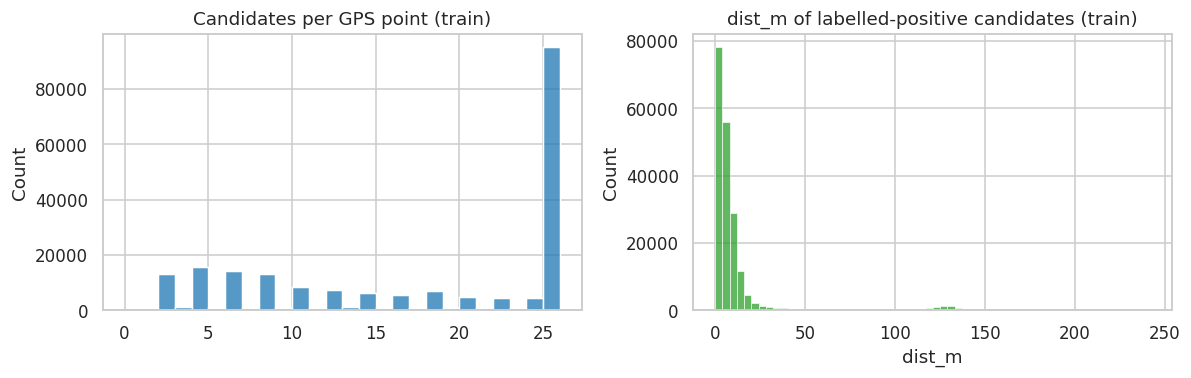

In [ ]:
# Evidence for the radius choice (TRAIN): miss rate vs radius, from aligned point->true-arc distances.
dd = {}
for part in PARTS:
    for tid in TRIP_IDS[part]:
        T = load_trip(part, tid); dd[(part, tid)] = pc.label_points(T["track"], T["nodes"], T["arcs"], T["route"], LABEL_R).true_dist_m.values
rg = [20, 30, 40, 50, 60, 80, 100, 150]
miss = pd.DataFrame({p: [np.concatenate([v for k, v in dd.items() if k[0] == p]).__gt__(R).mean() for R in rg] for p in PARTS}, index=pd.Index(rg, name="radius_m"))
print("Candidate miss rate by radius (ignores the MAX_K cap):"); display(miss.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cnt = out["train"].groupby(["trip_id", "point_idx"]).size()
sns.histplot(cnt, bins=range(0, MAX_K + 2), ax=ax[0], color=PAL["train"]); ax[0].set_title("Candidates per GPS point (train)")
sns.histplot(out["train"].query("label==1").dist_m, bins=60, ax=ax[1], color="#2ca02c"); ax[1].set_title("dist_m of labelled-positive candidates (train)")
plt.tight_layout(); plt.savefig(f"{FIG}/candidate_stats.png"); plt.show()

## 14. Export everything for the report & GitHub

In [ ]:
zip_path = shutil.make_archive("pathsnap_eda_outputs", "zip", OUT)
print("Created", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)")
print("Contents:", sum(len(f) for _, _, f in os.walk(OUT)), "files")
try:
    from google.colab import files
    files.download(zip_path)          # downloads figures, maps (HTML), CSV and findings.txt
except Exception:
    print("(Not running in Colab - find the zip in the working directory.)")
# Optional: copy to Drive instead
# from google.colab import drive; drive.mount("/content/drive"); shutil.copy(zip_path, "/content/drive/MyDrive/")

Created /content/pathsnap_eda_outputs.zip (3.6 MB)
Contents: 19 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>